--- KALIBRATIE TESTVIDEO ---
Pivot (x_0, y_0): (1134.63, -811.21) px
Straal R: 490.62 px
Schaal: 0.0416 cm/px



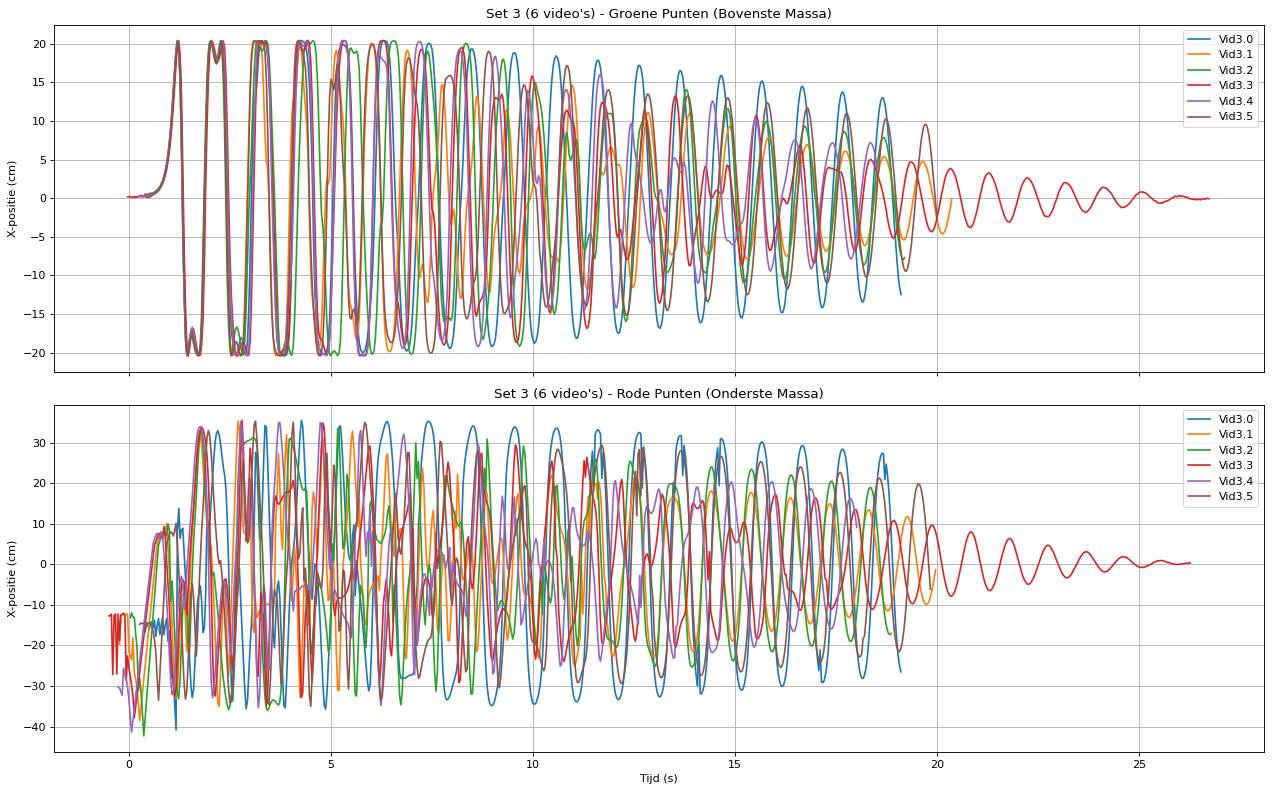

Opgeslagen: canonical_Vid3.0.csv
Opgeslagen: canonical_Vid3.1.csv
Opgeslagen: canonical_Vid3.2.csv
Opgeslagen: canonical_Vid3.3.csv
Opgeslagen: canonical_Vid3.4.csv
Opgeslagen: canonical_Vid3.5.csv


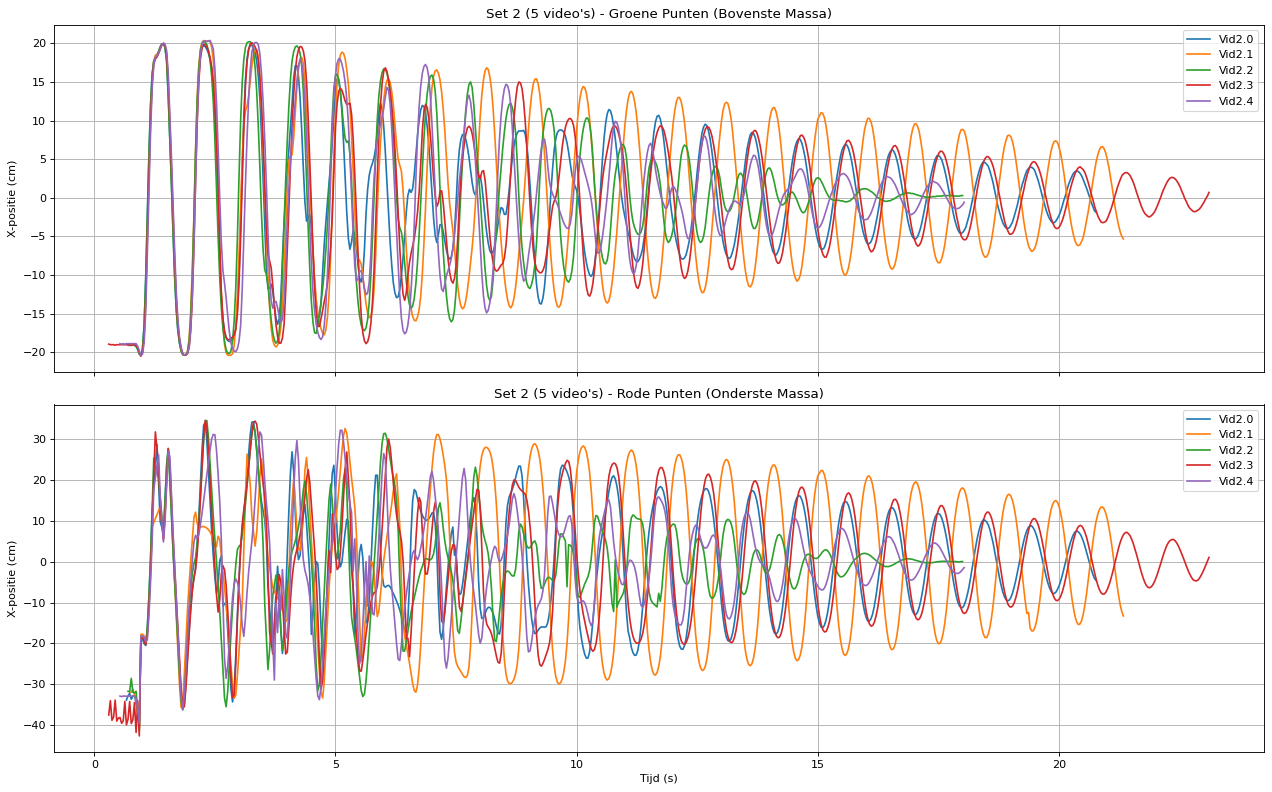

Opgeslagen: canonical_Vid2.0.csv
Opgeslagen: canonical_Vid2.1.csv
Opgeslagen: canonical_Vid2.2.csv
Opgeslagen: canonical_Vid2.3.csv
Opgeslagen: canonical_Vid2.4.csv


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import linregress



# set 3
filelist_red = [
    "Vid3.0_TRACKED-RED.csv",
    "Vid3.1_TRACKED-RED.csv",
    "Vid3.2_TRACKED-RED.csv",
    "Vid3.3_TRACKED-RED.csv",
    "Vid3.4_TRACKED-RED.csv",
    "Vid3.5_TRACKED-RED.csv"
]

filelist_green = [
    "Vid3.0_TRACKED-GREEN.csv",
    "Vid3.1_TRACKED-GREEN.csv",
    "Vid3.2_TRACKED-GREEN.csv",
    "Vid3.3_TRACKED-GREEN.csv",
    "Vid3.4_TRACKED-GREEN.csv",
    "Vid3.5_TRACKED-GREEN.csv"
]

# set 2
filelist_red2 = [
    "Vid2.0_TRACKED-RED.csv",
    "Vid2.1_TRACKED-RED.csv",
    "Vid2.2_TRACKED-RED.csv",
    "Vid2.3_TRACKED-RED.csv",
    "Vid2.4_TRACKED-RED.csv"
]

filelist_green2 = [
    "Vid2.0_TRACKED-GREEN.csv",
    "Vid2.1_TRACKED-GREEN.csv",
    "Vid2.2_TRACKED-GREEN.csv",
    "Vid2.3_TRACKED-GREEN.csv",
    "Vid2.4_TRACKED-GREEN.csv"
]


file = pd.read_csv("NightCap_2677A448_test.csv") #Rood
file2 = pd.read_csv("NightCap_2677A448_test_Green.csv") # Groen

# Experiment parameters uit de tabel (SI-eenheden: m en kg)
L1_cm = 20.4   # 20.4 cm
L2_cm = 16.02  # 16.02 cm
m1 = 0.5406    # 540.6 g -> kg
m2 = 0.2001    # 200.1 g -> kg
l1 = L1_cm / 100.0
l2 = L2_cm / 100.0

target_start_time = 1.0  # Vaste gewenste starttijd op de tijdsas (s)


# ==========================================
# 2. HULPFUNCTIES
# ==========================================

def circlefit(data, x_0, y_0, R):
    """Berekent de afwijking van een cirkel voor pivot-bepaling."""
    n = len(data) // 2
    x = data[:n]
    y = data[n:]
    return np.sqrt((x - x_0)**2 + (y - y_0)**2) - R


# ==========================================
# 3. TEST / KALIBRATIEBESTAND VERWERKING
# ==========================================

try:
    file_test_red = pd.read_csv("NightCap_2677A448_test.csv").dropna(subset=["x", "y", "time_s"])
    file_test_green = pd.read_csv("NightCap_2677A448_test_Green.csv").dropna(subset=["x", "y", "time_s"])

    x_test = file_test_green["x"].to_numpy()
    y_test = -file_test_green["y"].to_numpy()
    data_test = np.concatenate([x_test, y_test])
    target_test = np.zeros(len(x_test))

    popt_test, _ = curve_fit(circlefit, data_test, target_test)
    x0_t, y0_t, R_t = popt_test[0], popt_test[1], popt_test[2]

    print("--- KALIBRATIE TESTVIDEO ---")
    print(f"Pivot (x_0, y_0): ({x0_t:.2f}, {y0_t:.2f}) px")
    print(f"Straal R: {R_t:.2f} px")
    print(f"Schaal: {L1_cm / R_t:.4f} cm/px\n")
except Exception as e:
    print(f"Testbestand overgeslagen of niet gevonden: {e}\n")


# ==========================================
# 4. HOOFDFUNCTIE VOOR HET VERWERKEN VAN EEN SET
# ==========================================
m_per_px_array = np.array([])
def process_and_plot_dataset(list_green, list_red, dataset_title="Dataset"):
    x_0_array = np.array([])
    y_0_array = np.array([])
    min_inx_array = np.array([])
    cm_per_px_array = np.array([])

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), dpi=80, sharex=True)

    # A. Groene punten (Bovenste Massa) & Pivot Bepaling
    for name in list_green:
        file = pd.read_csv(name).dropna(subset=["x", "y", "time_s"]) 
        t2 = file["time_s"].to_numpy()
        x2 = file["x"].to_numpy()
        y2 = -file["y"].to_numpy()

        data = np.concatenate([x2, y2])
        target = np.zeros(len(x2))
        popt, _ = curve_fit(circlefit, data, target)

        x_0, y_0, R = popt[0], popt[1], popt[2]

        m_per_px = (L1_cm / 100) / R
        cm_per_px = m_per_px * 100
        cm_per_px_array = np.append(cm_per_px_array, cm_per_px)
        

        # Coördinaten omzetten van pixels naar meters,
        # met het draaipunt als oorsprong
        x2 = (x2 - x_0) * m_per_px
        y2 = (y2 - y_0) * m_per_px

        x_0_array = np.append(x_0_array, x_0)
        y_0_array = np.append(y_0_array, y_0)

        # --- VERBETERDE UNIVERSELE START-DETECTIE ---
        # Zoek het moment waarop de pendule de eerste grote beweging/daling maakt
        dx = np.abs(np.diff(x2))
        threshold = np.max(dx) * 0.15  # Drempel op 15% van de maximale snelheid
        moving_indices = np.where(dx > threshold)[0]

        if len(moving_indices) > 0:
            min_idx = moving_indices[0]
        else:
            min_idx = np.argmin(dx)

        min_inx_array = np.append(min_inx_array, min_idx)

        t2_aligned = (t2 - t2[min_idx]) + target_start_time
        ax1.plot(t2_aligned, x2 * 100, label=name.split('_')[0])

    ax1.set_title(f"{dataset_title} - Groene Punten (Bovenste Massa)")
    ax1.set_ylabel("X-positie (cm)")
    ax1.grid(True)
    ax1.legend()

    # B. Rode punten (Onderste Massa)
    for n, name in enumerate(list_red):
        file = pd.read_csv(name).dropna(subset=["x", "y", "time_s"])
        t = file["time_s"].to_numpy()
        x = file["x"].to_numpy() - x_0_array[n]

        align_idx = int(min_inx_array[n])
        t_aligned = (t - t[align_idx]) + target_start_time

        ax2.plot(t_aligned, x * cm_per_px_array[n], label=name.split('_')[0])

    ax2.set_title(f"{dataset_title} - Rode Punten (Onderste Massa)")
    ax2.set_xlabel("Tijd (s)")
    ax2.set_ylabel("X-positie (cm)")
    ax2.grid(True)
    ax2.legend()

    plt.tight_layout()
    plt.show()

    # C. Exporteer Canonieke Coördinaten (Phi, Omega, P) per bestand naar CSV
    for n in range(len(list_green)):
        file_g = pd.read_csv(list_green[n]).dropna(subset=["x", "y", "time_s"])
        file_r = pd.read_csv(list_red[n]).dropna(subset=["x", "y", "time_s"])

        min_len = min(len(file_g), len(file_r))
        file_g = file_g.iloc[:min_len]
        file_r = file_r.iloc[:min_len]

        t = file_g["time_s"].to_numpy()
        m_per_px = cm_per_px_array[n] / 100.0

        x1 = (file_g["x"].to_numpy() - x_0_array[n]) * m_per_px
        y1 = (-file_g["y"].to_numpy() - y_0_array[n]) * m_per_px

        x2 = (file_r["x"].to_numpy() - x_0_array[n]) * m_per_px
        y2 = (-file_r["y"].to_numpy() - y_0_array[n]) * m_per_px

        phi1 = np.arctan2(x1, -y1)
        phi2 = np.arctan2(x2 - x1, -(y2 - y1))

        omega1 = np.gradient(phi1, t)
        omega2 = np.gradient(phi2, t)

        d_phi = phi1 - phi2
        p1 = (m1 + m2) * (l1**2) * omega1 + m2 * l1 * l2 * omega2 * np.cos(d_phi)
        p2 = m2 * (l2**2) * omega2 + m2 * l1 * l2 * omega1 * np.cos(d_phi)

        align_idx = int(min_inx_array[n])
        t_aligned = (t - t[align_idx]) + target_start_time

        df_out = pd.DataFrame({
            'time_s': t_aligned,
            'phi1_rad': phi1,
            'phi2_rad': phi2,
            'omega1_rad_s': omega1,
            'omega2_rad_s': omega2,
            'p1_kg_m2_s': p1,
            'p2_kg_m2_s': p2
        })

        filename = f"canonical_{list_green[n].split('_')[0]}.csv"
        df_out.to_csv(filename, index=False)
        print(f"Opgeslagen: {filename}")


# ==========================================
# 5. EXECUTION VAN DE TWEE DATASETS
# ==========================================

# Verwerk Set 3 (6 video's)
process_and_plot_dataset(filelist_green, filelist_red, dataset_title="Set 3 (6 video's)")

# Verwerk Set 2 (5 video's)
process_and_plot_dataset(filelist_green2, filelist_red2, dataset_title="Set 2 (5 video's)")

Vid3.0
Middelpunt: (641.53, -478.06) px
Straal: 300.48 px



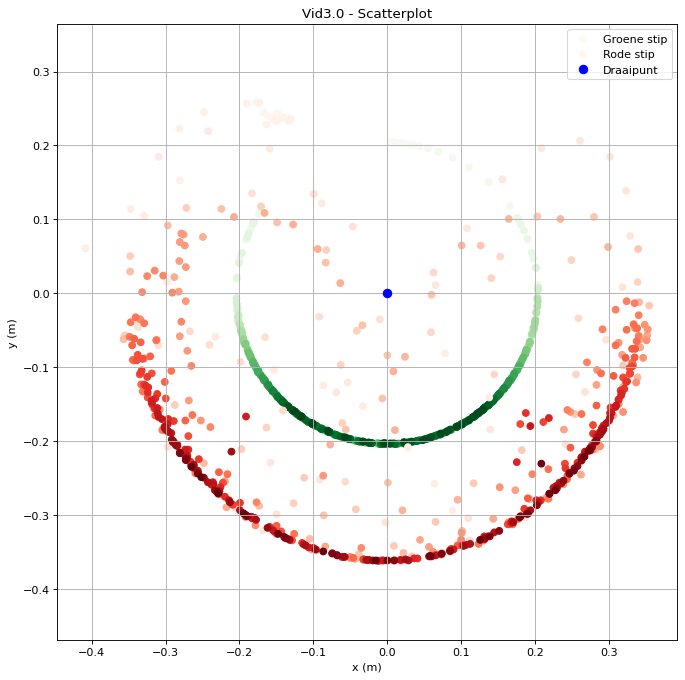

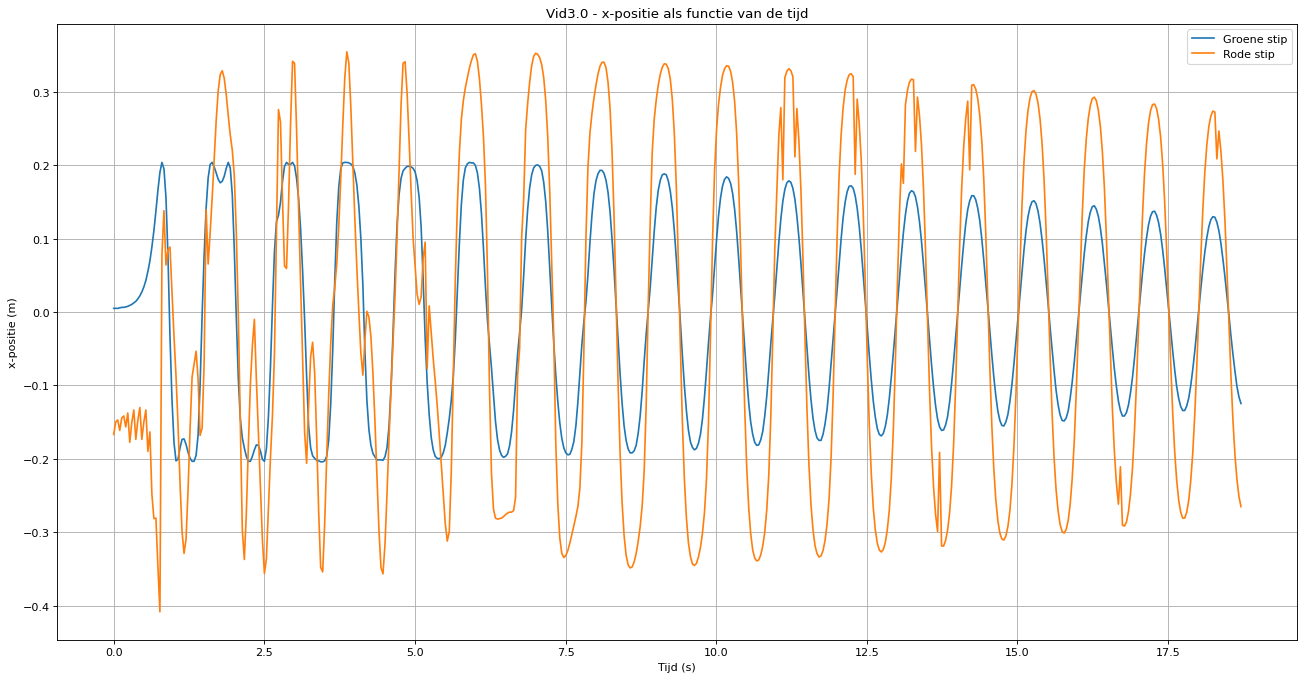

Vid3.1
Middelpunt: (602.48, -478.02) px
Straal: 300.38 px



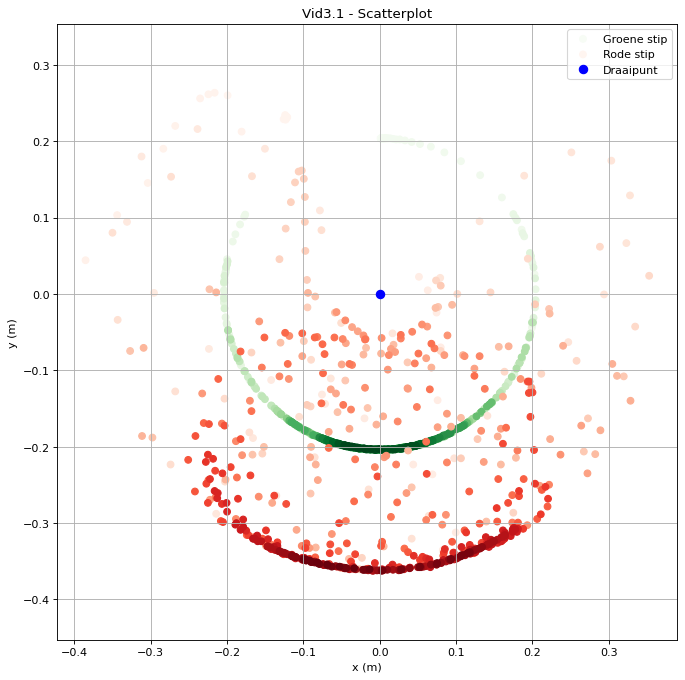

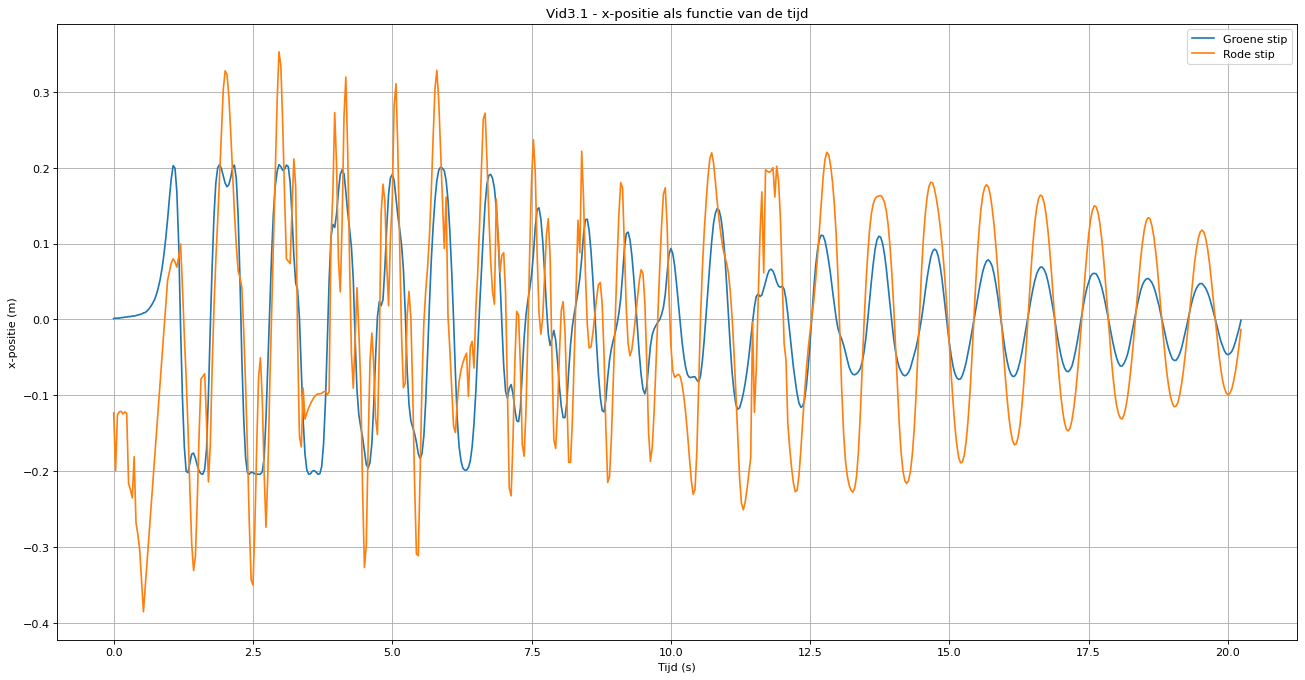

Vid3.2
Middelpunt: (633.53, -479.88) px
Straal: 300.57 px



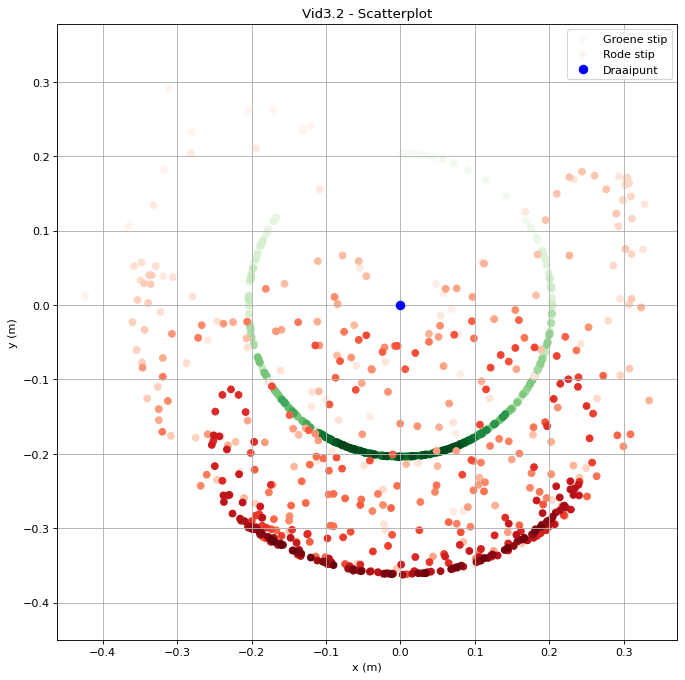

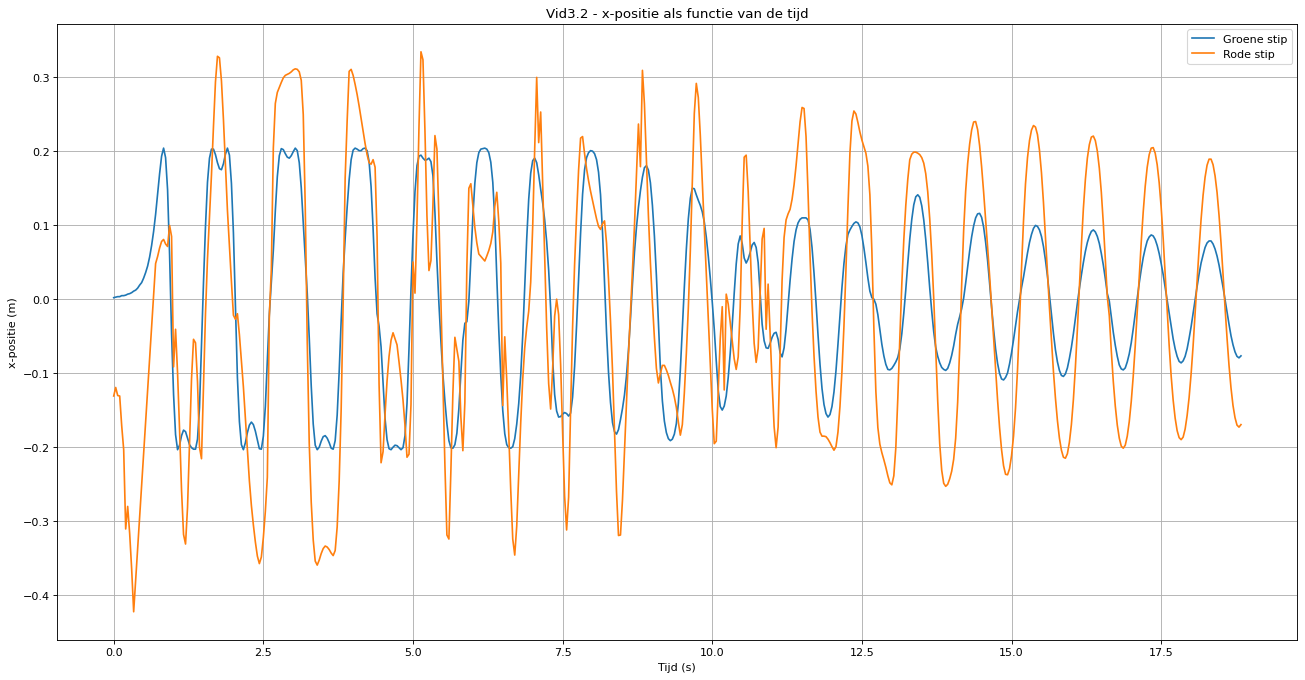

Vid3.3
Middelpunt: (613.30, -458.10) px
Straal: 300.38 px



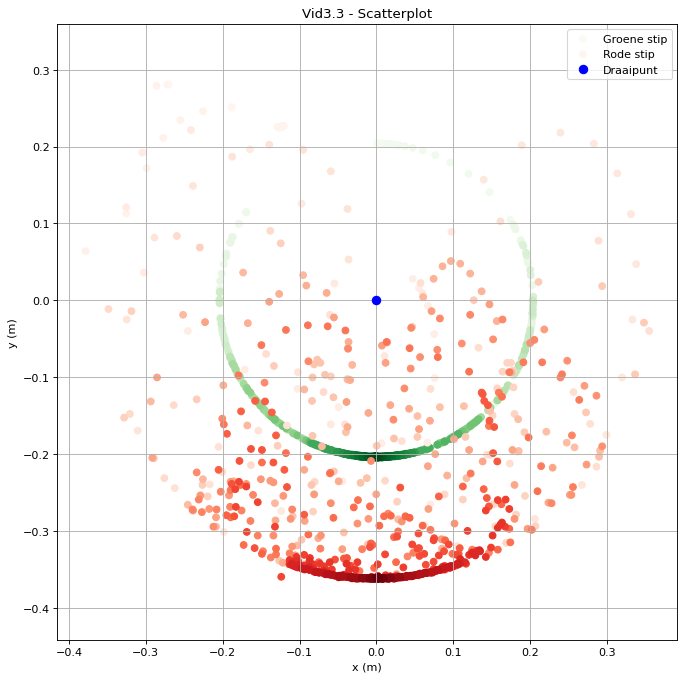

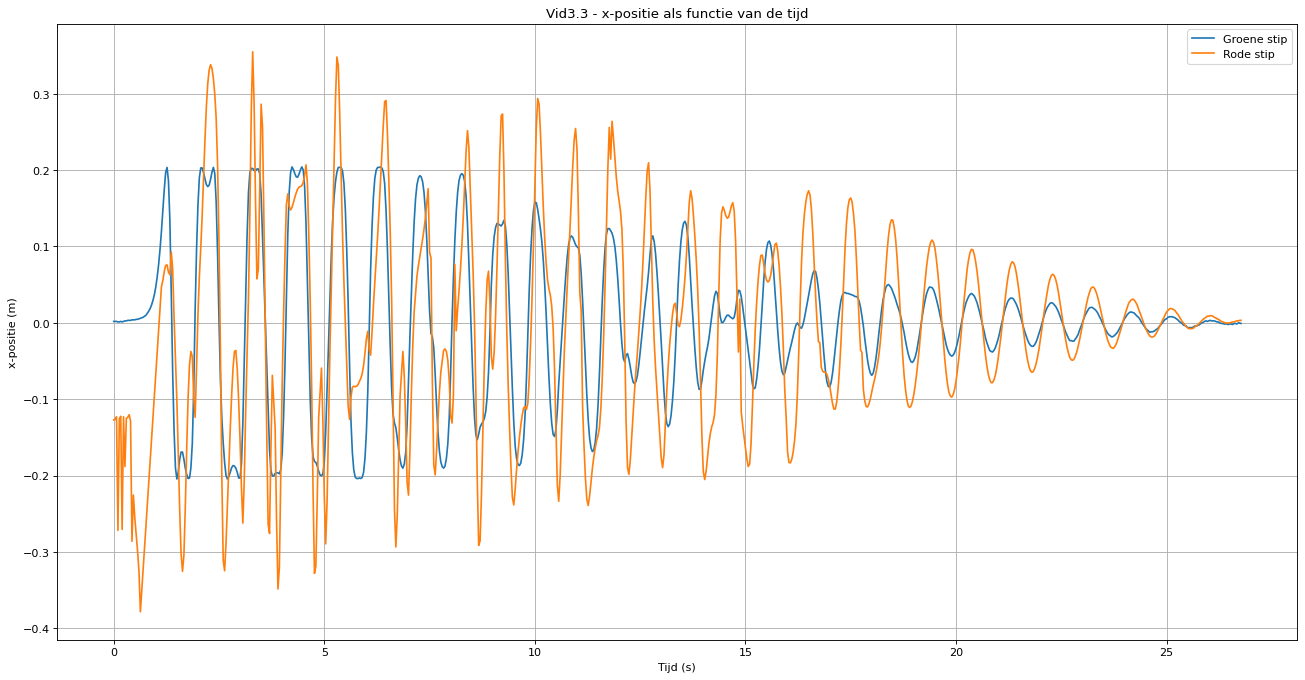

Vid3.4
Middelpunt: (614.23, -487.10) px
Straal: 300.62 px



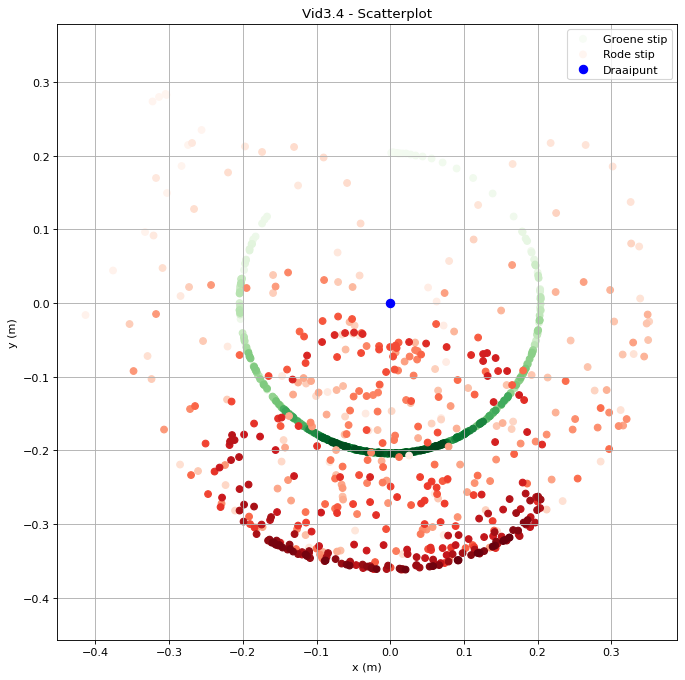

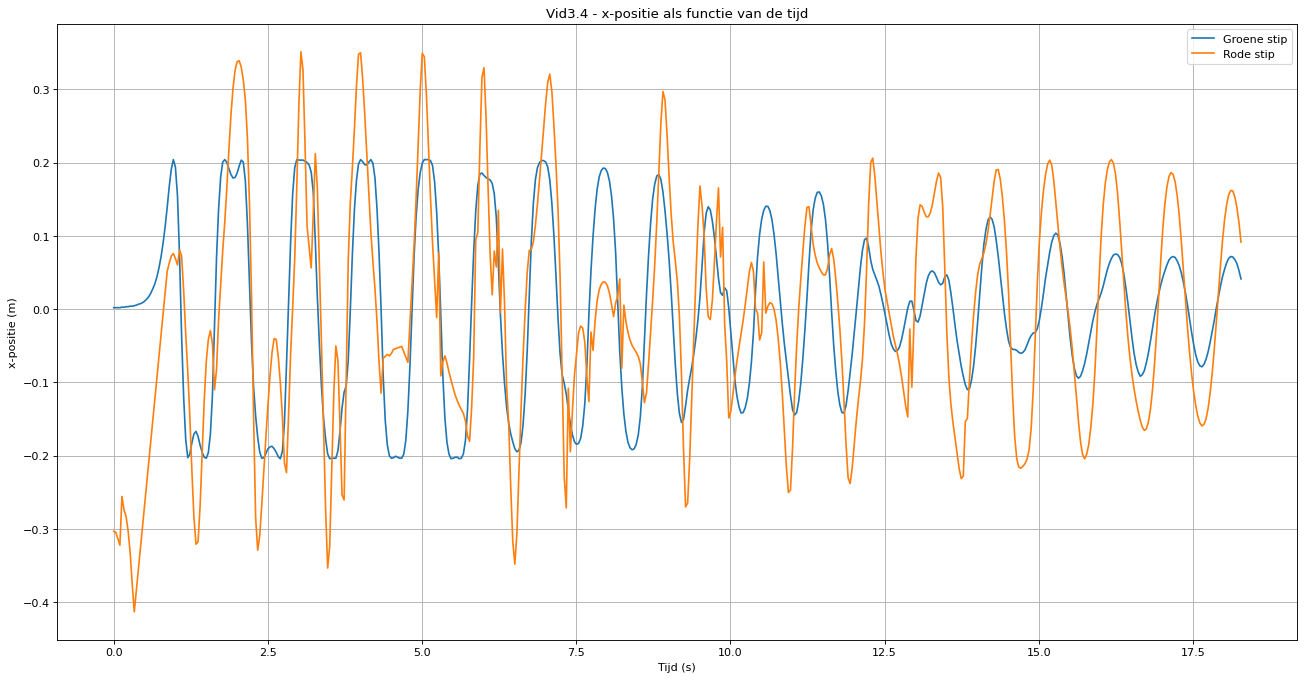

Vid3.5
Middelpunt: (609.23, -476.16) px
Straal: 300.24 px



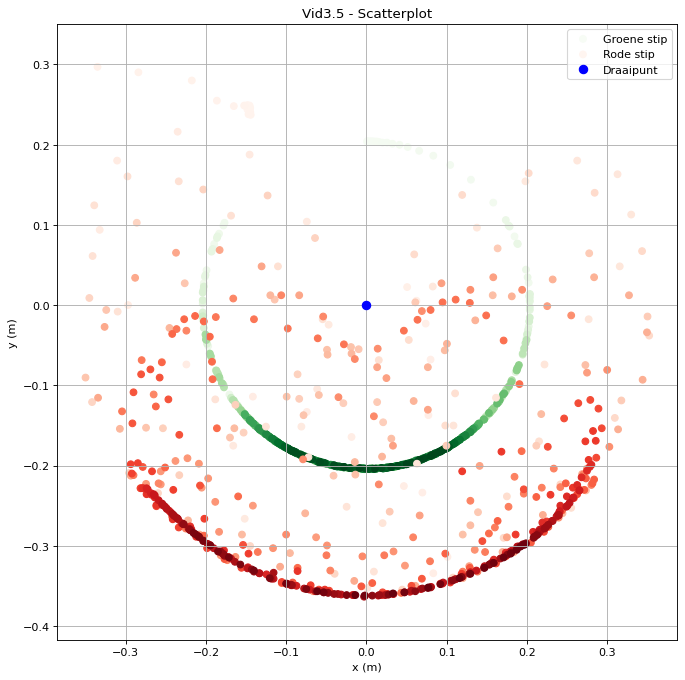

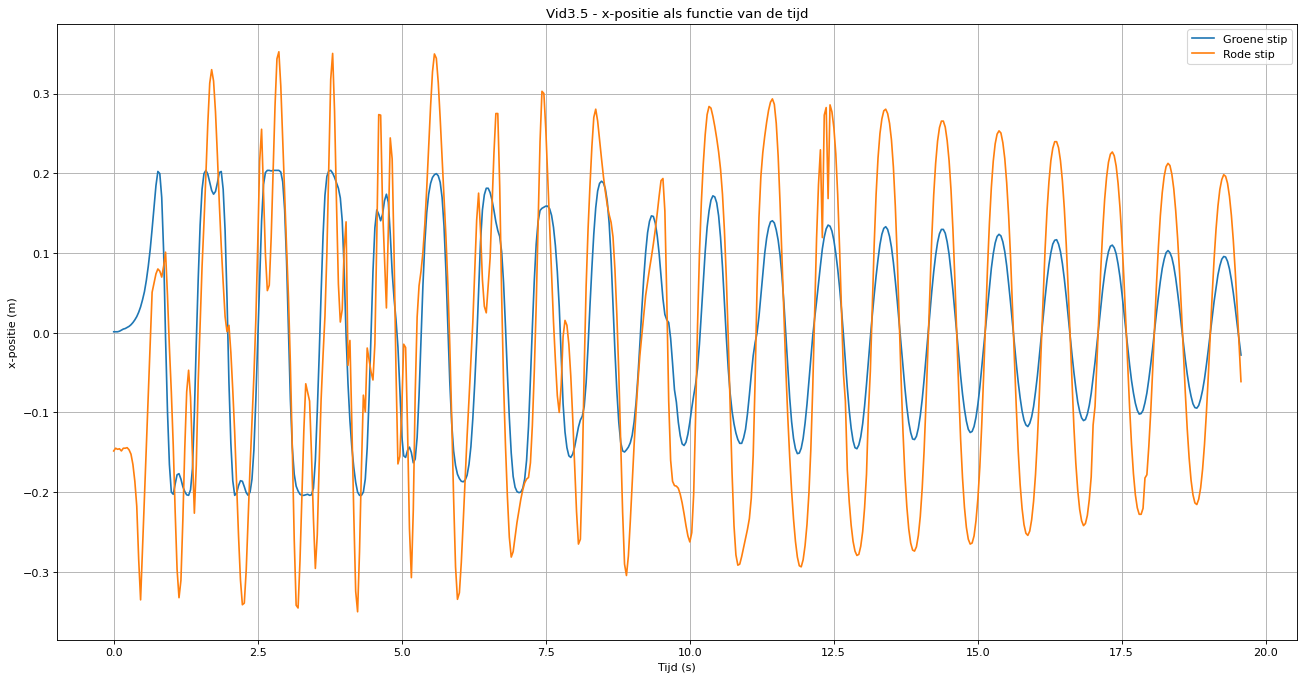

Vid2.0
Middelpunt: (634.68, -475.98) px
Straal: 302.22 px



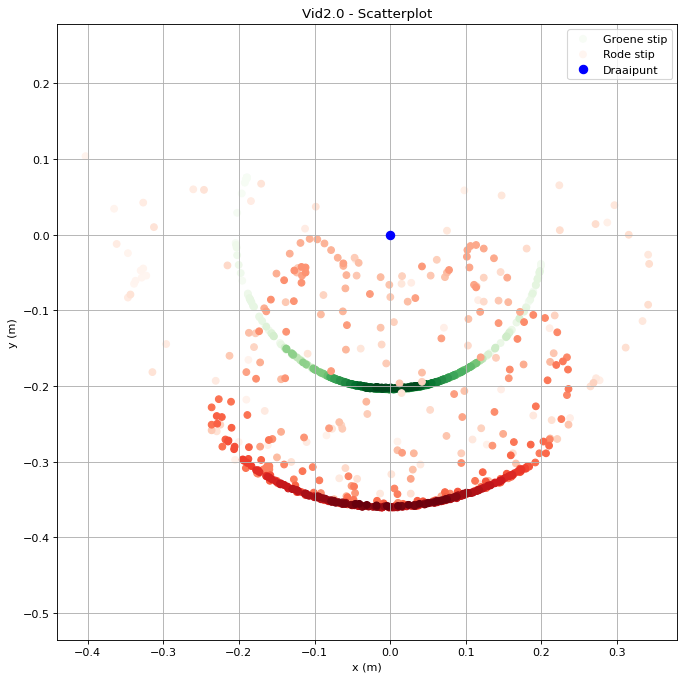

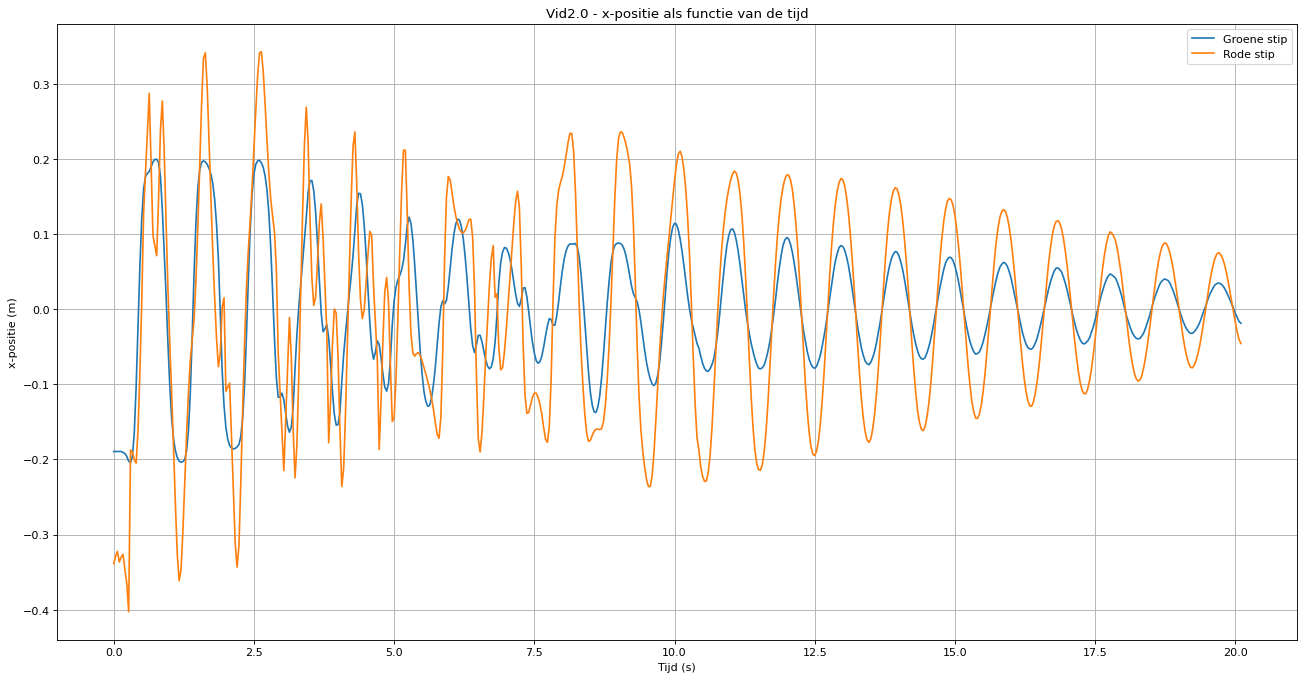

Vid2.1
Middelpunt: (625.79, -478.44) px
Straal: 301.90 px



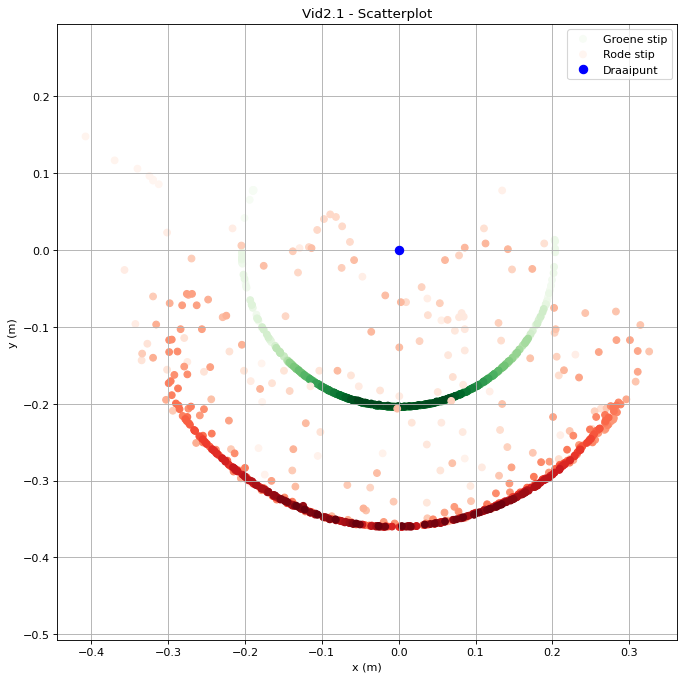

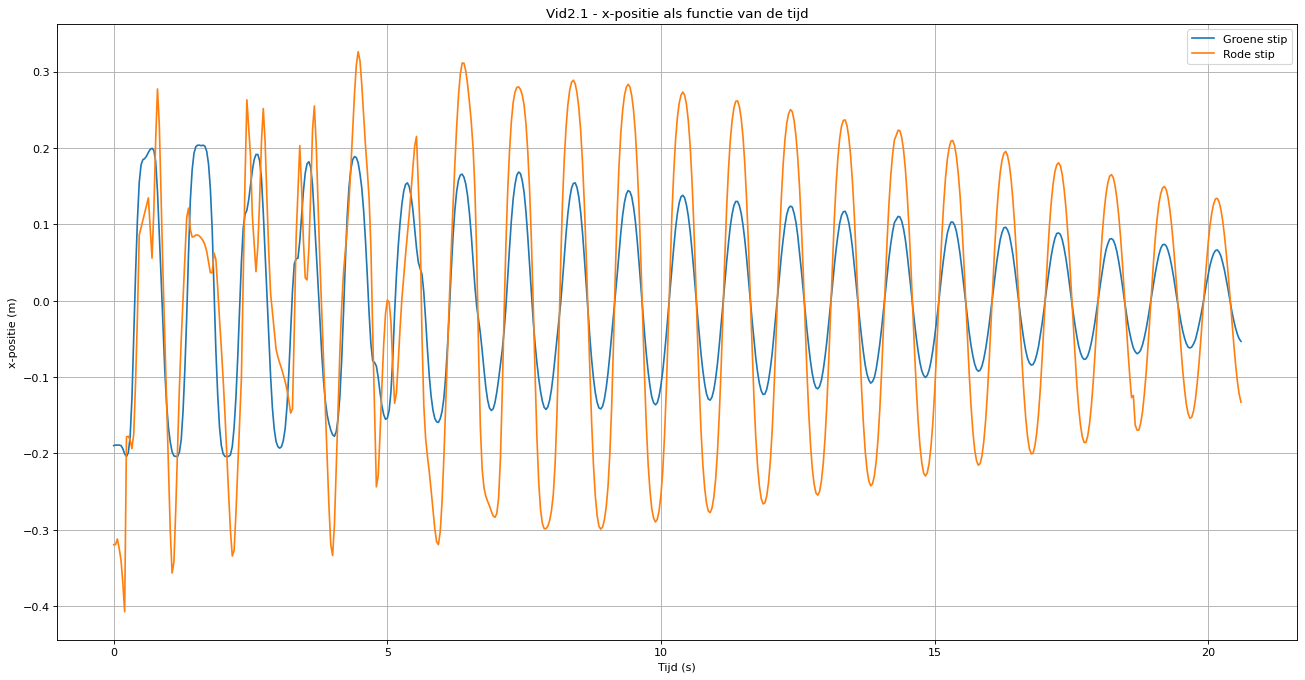

Vid2.2
Middelpunt: (647.73, -478.24) px
Straal: 301.98 px



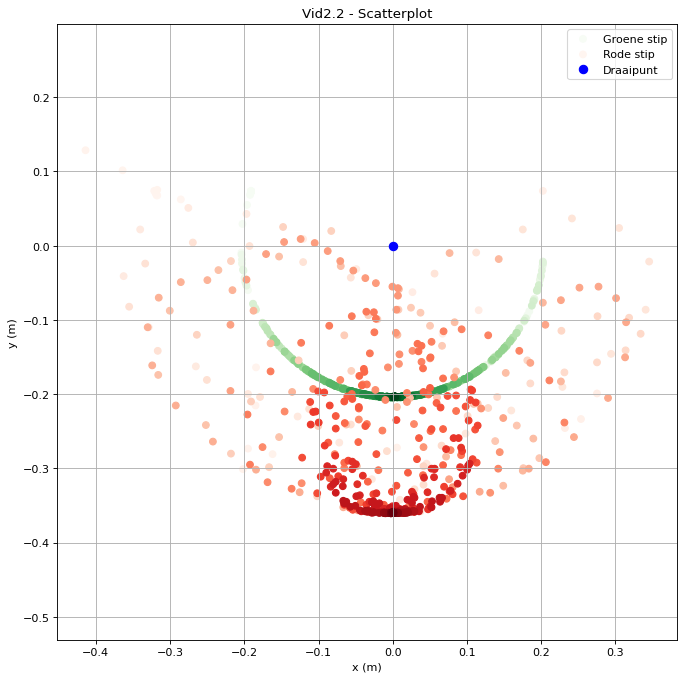

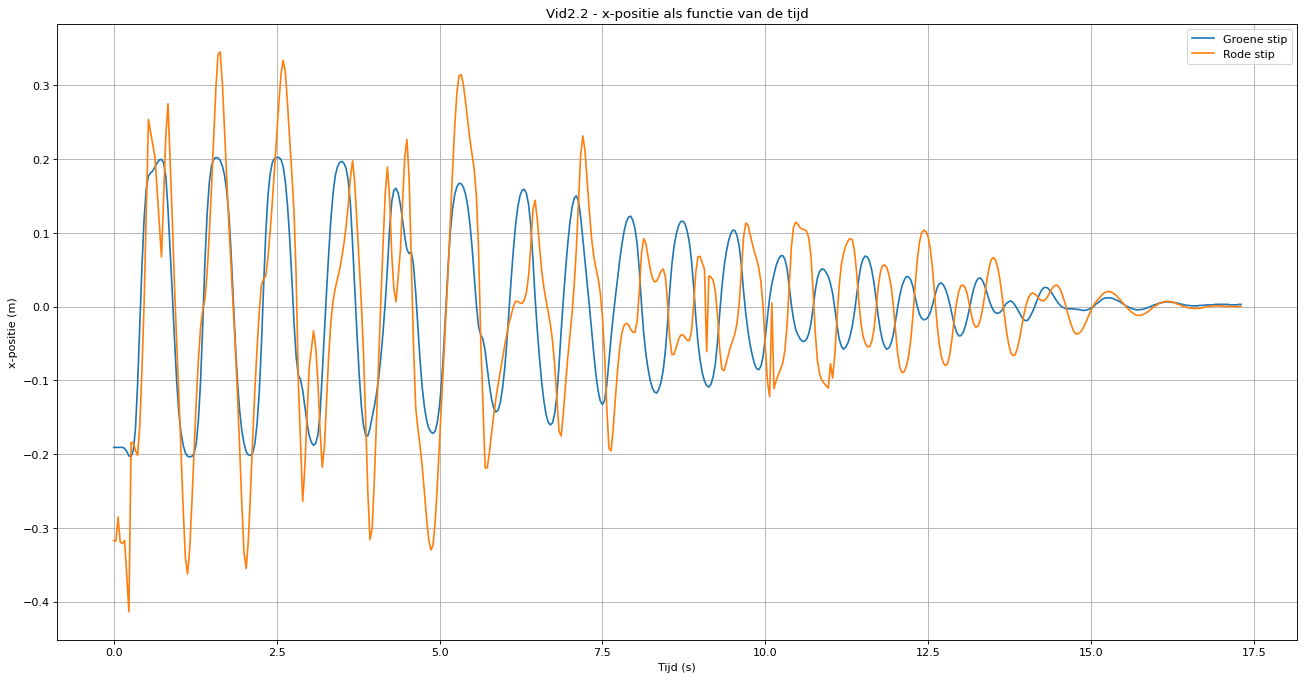

Vid2.3
Middelpunt: (643.70, -478.08) px
Straal: 302.07 px



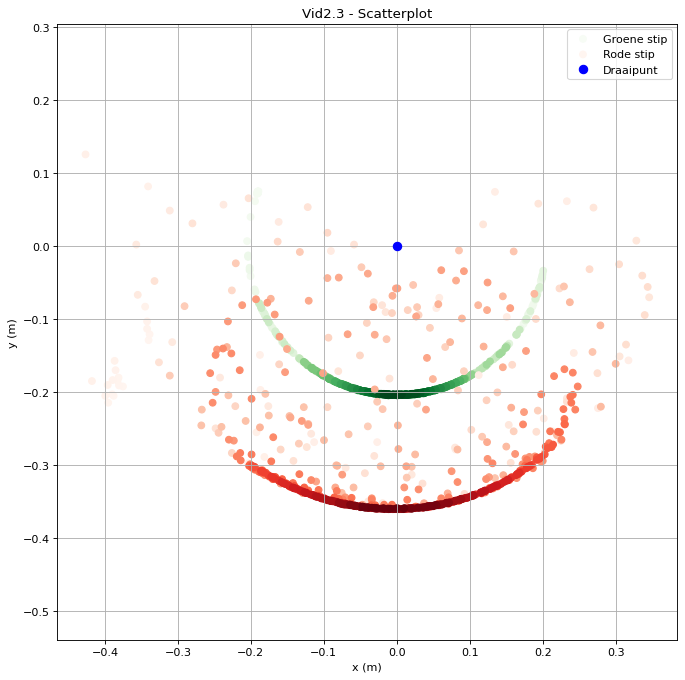

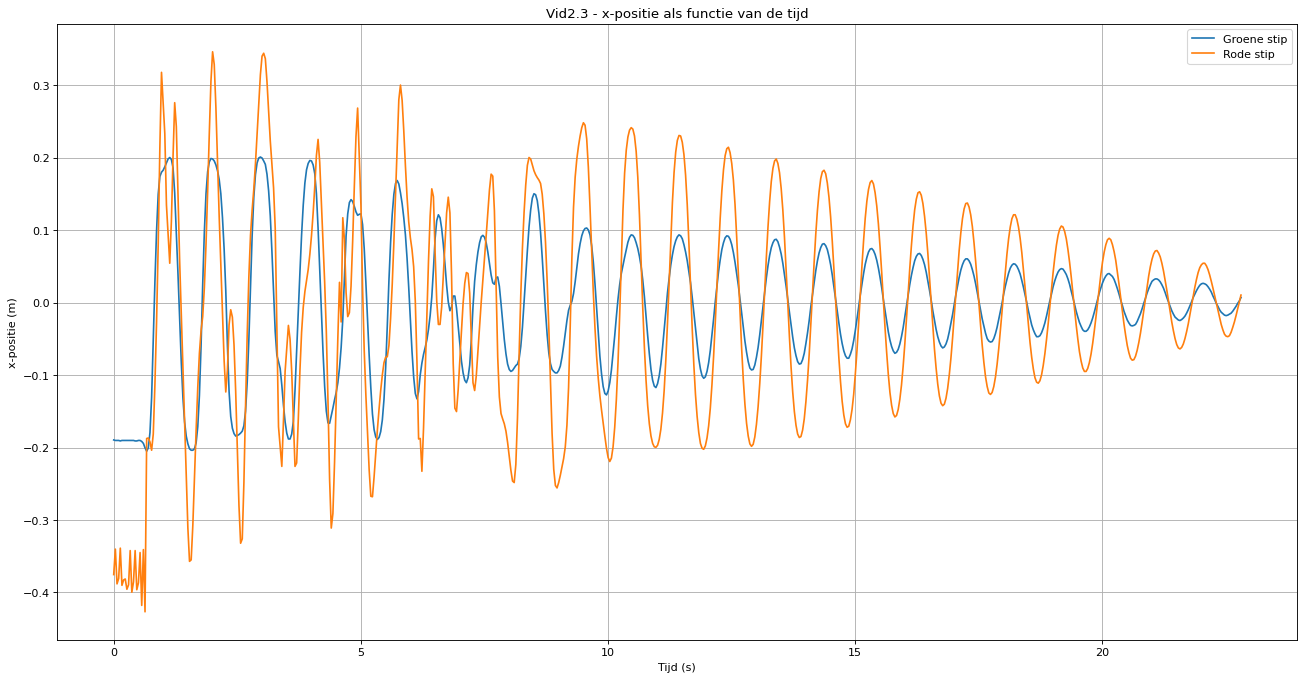

Vid2.4
Middelpunt: (635.49, -478.37) px
Straal: 301.75 px



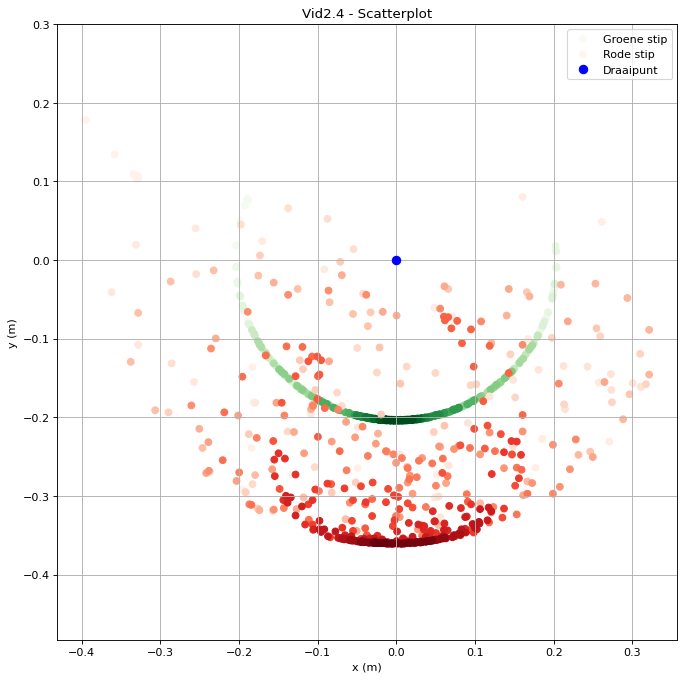

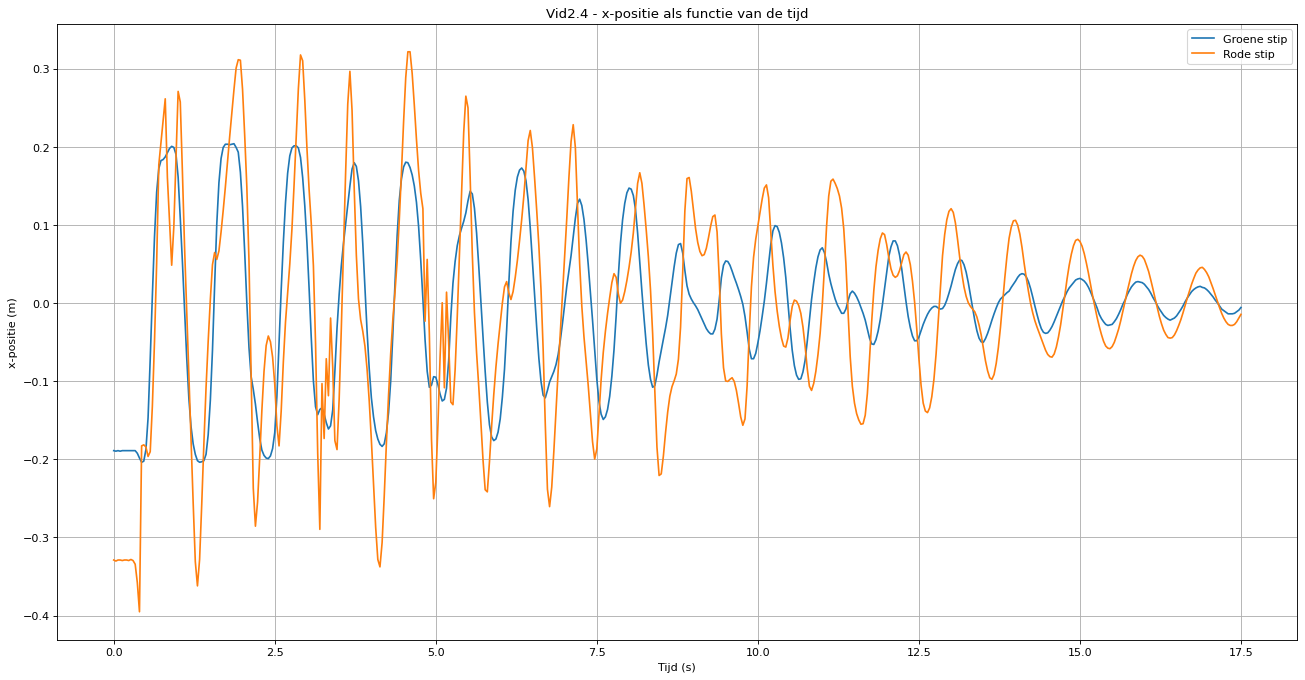

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


# ==========================================
# 1. CIRKELFIT VOOR HET MIDDELPUNT
# ==========================================

def circlefit(data, x_0, y_0, R):
    n = len(data) // 2
    x = data[:n]
    y = data[n:]
    return np.sqrt((x - x_0)**2 + (y - y_0)**2) - R


# ==========================================
# 2. PLOT VAN ÉÉN VIDEO
# ==========================================

def plot_video(file_green, file_red, title):

    # Groene stip
    green = pd.read_csv(file_green)
    t2 = green["time_s"].to_numpy()
    x2 = green["x"].to_numpy()
    y2 = -green["y"].to_numpy()

    mask = np.isfinite(t2) & np.isfinite(x2) & np.isfinite(y2)
    t2, x2, y2 = t2[mask], x2[mask], y2[mask]

    # Rode stip
    red = pd.read_csv(file_red)
    t = red["time_s"].to_numpy()
    x = red["x"].to_numpy()
    y = -red["y"].to_numpy()

    mask = np.isfinite(t) & np.isfinite(x) & np.isfinite(y)
    t, x, y = t[mask], x[mask], y[mask]

    # Middelpunt bepalen met de groene stip
    data = np.concatenate([x2, y2])
    target = np.zeros(len(x2))

    popt, cov = curve_fit(circlefit, data, target)
    x_0, y_0, R = popt

    print(f"{title}")
    print(f"Middelpunt: ({x_0:.2f}, {y_0:.2f}) px")
    print(f"Straal: {R:.2f} px\n")

    # Omzetting van pixels naar meters
    L1 = 0.204  # Lengte bovenste pendulum in meters
    m_per_px = L1 / R

    # Beide stippen hetzelfde middelpunt geven
    x2 = (x2 - x_0) * m_per_px
    y2 = (y2 - y_0) * m_per_px

    x = (x - x_0) * m_per_px
    y = (y - y_0) * m_per_px

    # ==========================================
    # PLOT 1: SCATTERPLOT VAN BEIDE STIPPEN
    # ==========================================

    plt.figure(figsize=(10, 10), dpi=80)
    plt.title(f"{title} - Scatterplot")

    plt.scatter(x2, y2, c=t2, cmap="Greens", label="Groene stip")
    plt.scatter(x, y, c=t, cmap="Reds", label="Rode stip")

    plt.plot(0, 0, "b.", markersize=15, label="Draaipunt")

    plt.xlabel("x (m)")
    plt.ylabel("y (m)")
    plt.axis("equal")
    plt.grid(True)
    plt.legend()
    plt.show()

    # ==========================================
    # PLOT 2: X-POSITIE ALS FUNCTIE VAN DE TIJD
    # ==========================================

    plt.figure(figsize=(20, 10), dpi=80)
    plt.title(f"{title} - x-positie als functie van de tijd")

    plt.plot(t2, x2, label="Groene stip")
    plt.plot(t, x, label="Rode stip")

    plt.xlabel("Tijd (s)")
    plt.ylabel("x-positie (m)")
    plt.grid(True)
    plt.legend()
    plt.show()


# ==========================================
# 3. SET 3: ZES VIDEO'S
# ==========================================

for green_file, red_file in zip(filelist_green, filelist_red):
    plot_video(green_file, red_file, green_file.split("_")[0])


# ==========================================
# 4. SET 2: VIJF VIDEO'S
# ==========================================

for green_file, red_file in zip(filelist_green2, filelist_red2):
    plot_video(green_file, red_file, green_file.split("_")[0])

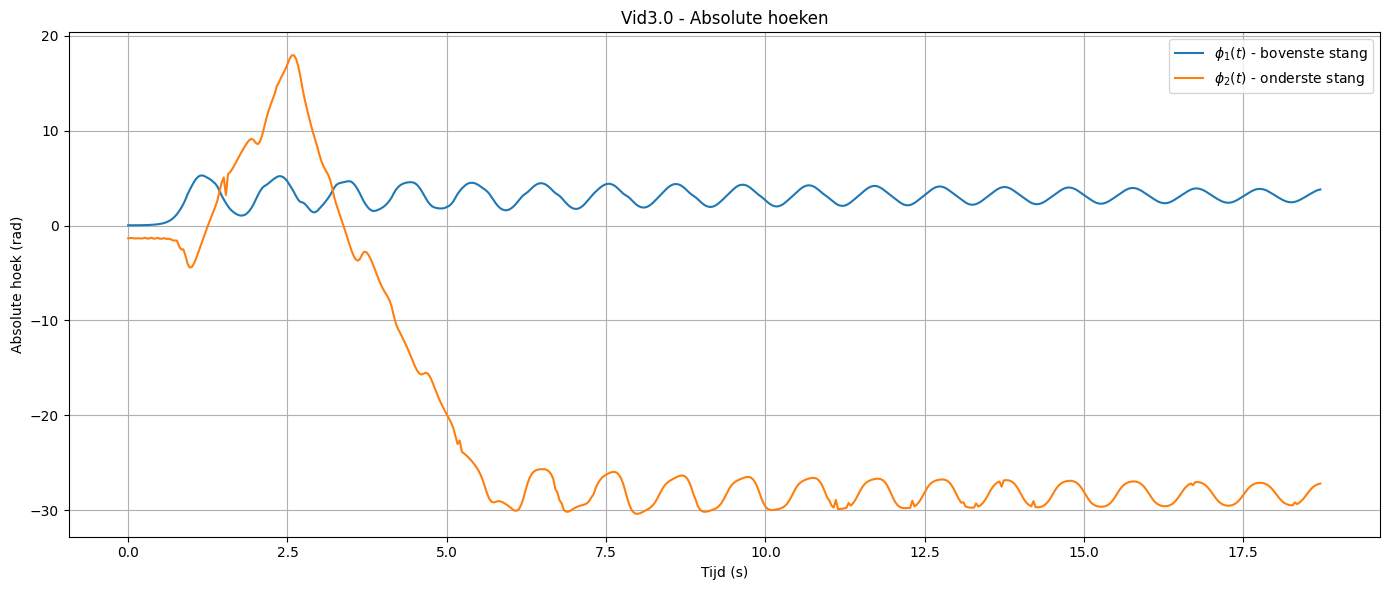

Vid3.0: 558 gezamenlijke geldige frames van 562 groene en 562 rode rijen.
Tijdsinterval: 0.000–18.710 s
Vid3.0:
  phi1 begin: 1.42°
  phi1 einde: 217.88°
  phi2 begin: -76.87°
  phi2 einde: -1557.99°
  phi1 eindrichting: 217.88°
  phi2 eindrichting: 242.01°


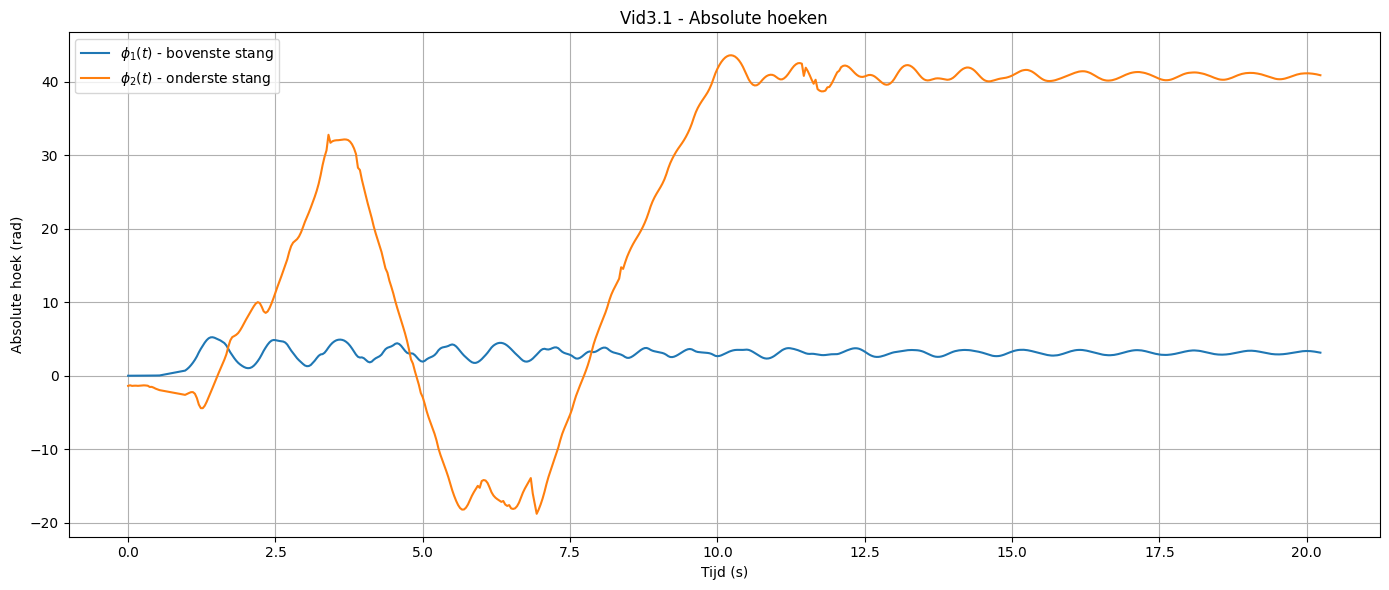

Vid3.1: 588 gezamenlijke geldige frames van 608 groene en 608 rode rijen.
Tijdsinterval: 0.000–20.233 s
Vid3.1:
  phi1 begin: 0.29°
  phi1 einde: 180.29°
  phi2 begin: -78.87°
  phi2 einde: 2344.44°
  phi1 eindrichting: 180.29°
  phi2 eindrichting: 184.44°


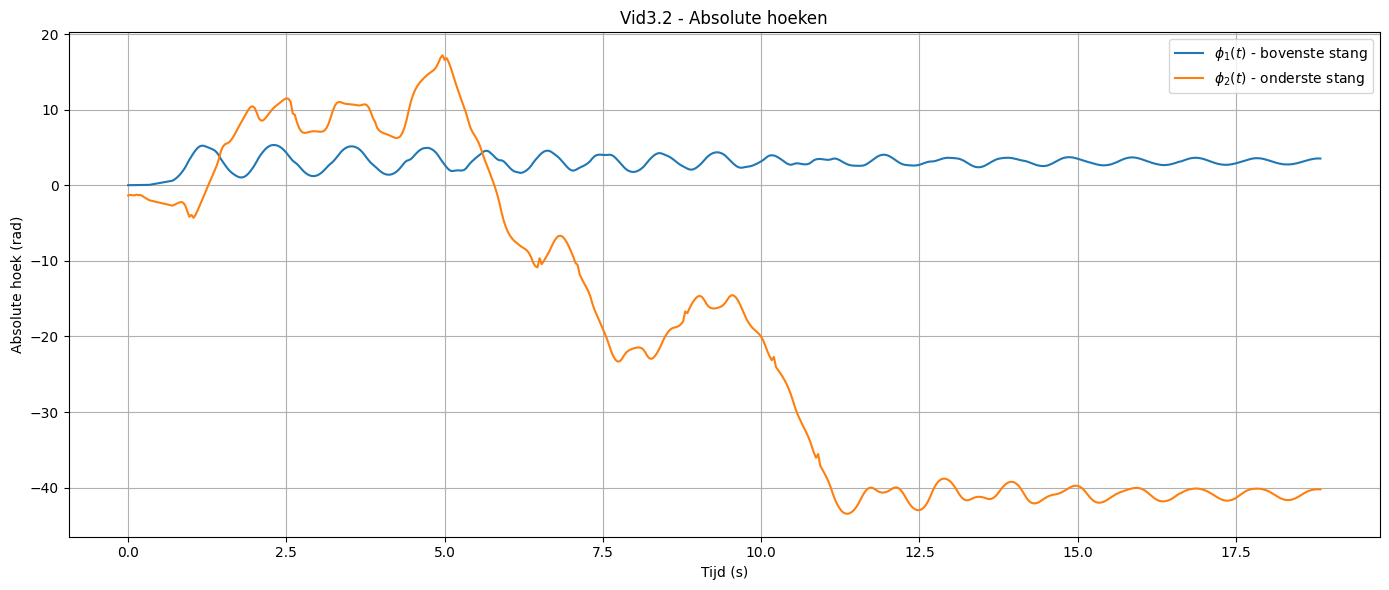

Vid3.2: 548 gezamenlijke geldige frames van 566 groene en 566 rode rijen.
Tijdsinterval: 0.000–18.833 s
Vid3.2:
  phi1 begin: 0.47°
  phi1 einde: 202.28°
  phi2 begin: -77.35°
  phi2 einde: -2304.35°
  phi1 eindrichting: 202.28°
  phi2 eindrichting: 215.65°


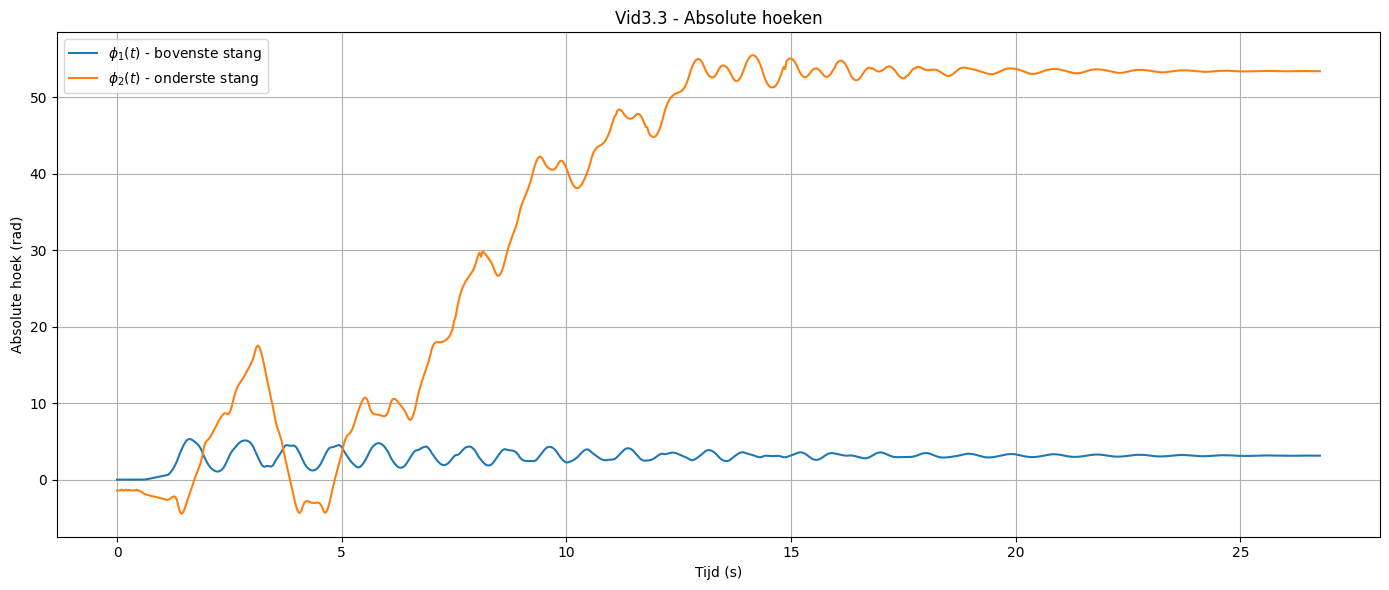

Vid3.3: 782 gezamenlijke geldige frames van 804 groene en 804 rode rijen.
Tijdsinterval: 0.000–26.767 s
Vid3.3:
  phi1 begin: 0.51°
  phi1 einde: 180.25°
  phi2 begin: -81.03°
  phi2 einde: 3058.52°
  phi1 eindrichting: 180.25°
  phi2 eindrichting: 178.52°


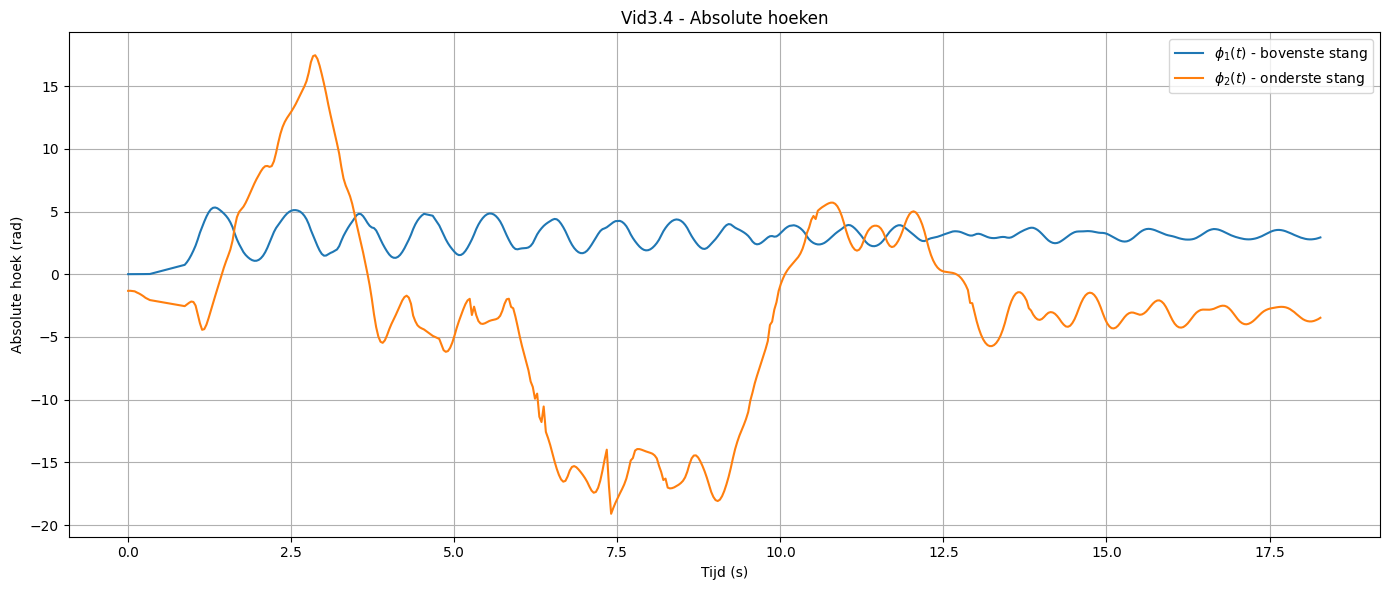

Vid3.4: 521 gezamenlijke geldige frames van 549 groene en 549 rode rijen.
Tijdsinterval: 0.000–18.280 s
Vid3.4:
  phi1 begin: 0.52°
  phi1 einde: 168.36°
  phi2 begin: -75.66°
  phi2 einde: -198.67°
  phi1 eindrichting: 168.36°
  phi2 eindrichting: 161.33°


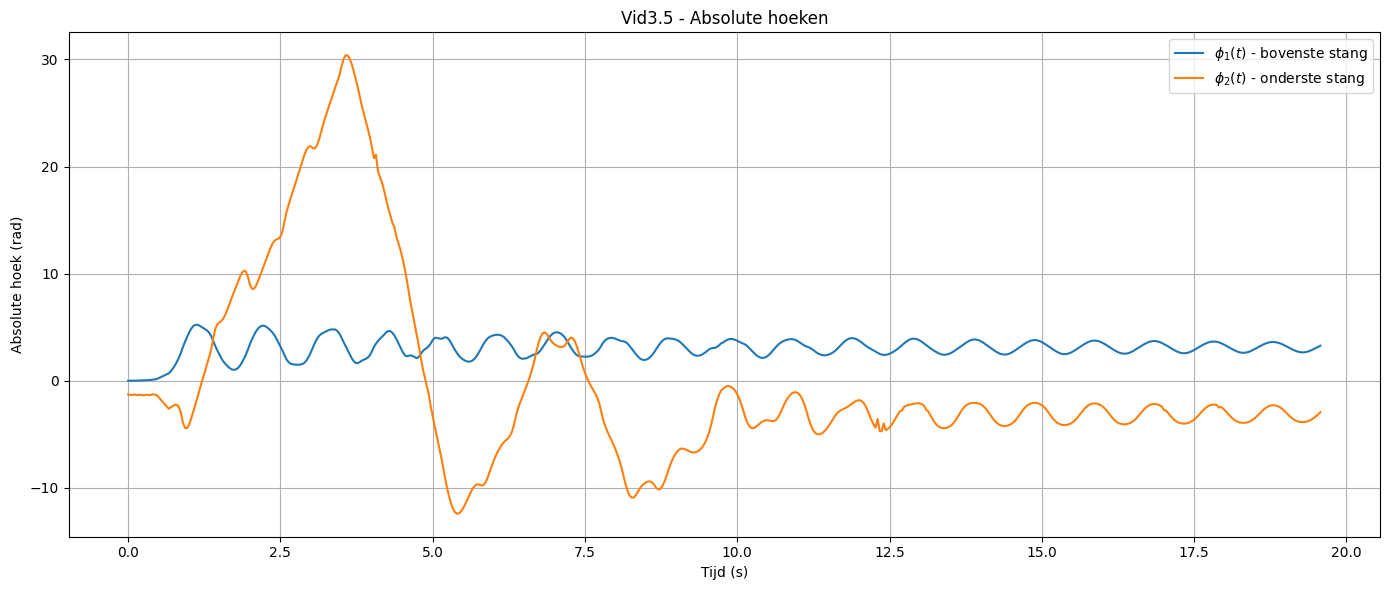

Vid3.5: 575 gezamenlijke geldige frames van 588 groene en 588 rode rijen.
Tijdsinterval: 0.000–19.572 s
Vid3.5:
  phi1 begin: 0.34°
  phi1 einde: 187.91°
  phi2 begin: -73.06°
  phi2 einde: -167.87°
  phi1 eindrichting: 187.91°
  phi2 eindrichting: 192.13°


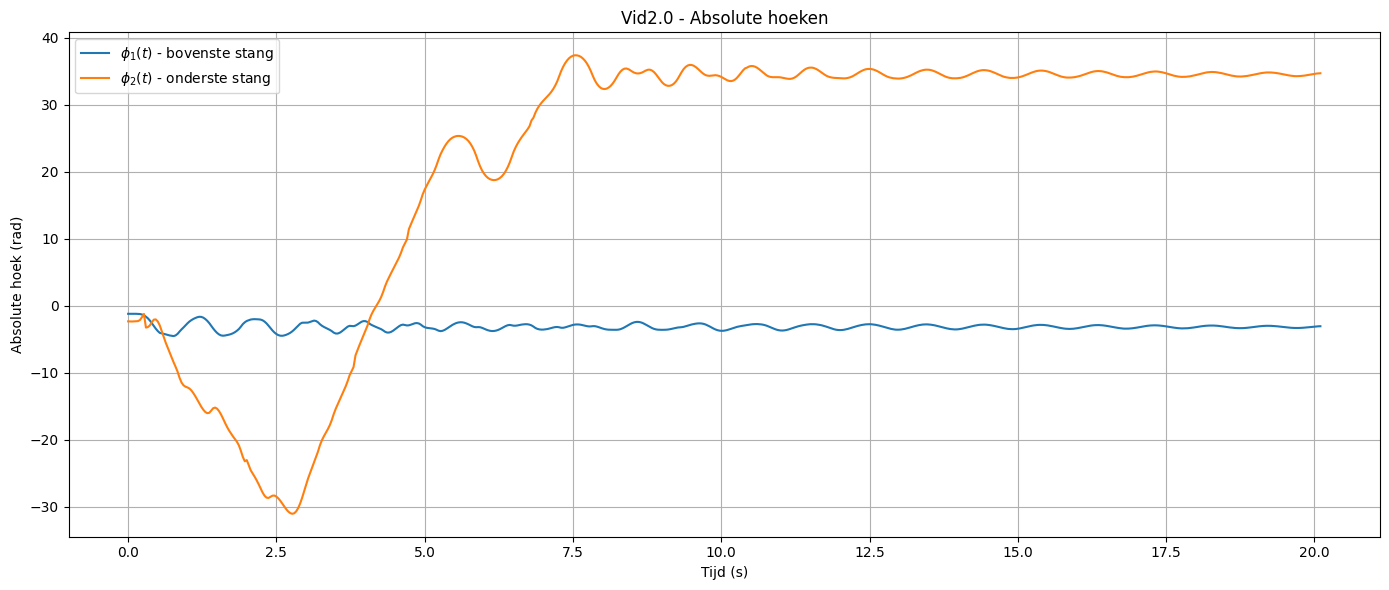

Vid2.0: 589 gezamenlijke geldige frames van 604 groene en 604 rode rijen.
Tijdsinterval: 0.000–20.100 s
Vid2.0:
  phi1 begin: -68.43°
  phi1 einde: -174.69°
  phi2 begin: -133.13°
  phi2 einde: 1989.91°
  phi1 eindrichting: 185.31°
  phi2 eindrichting: 189.91°


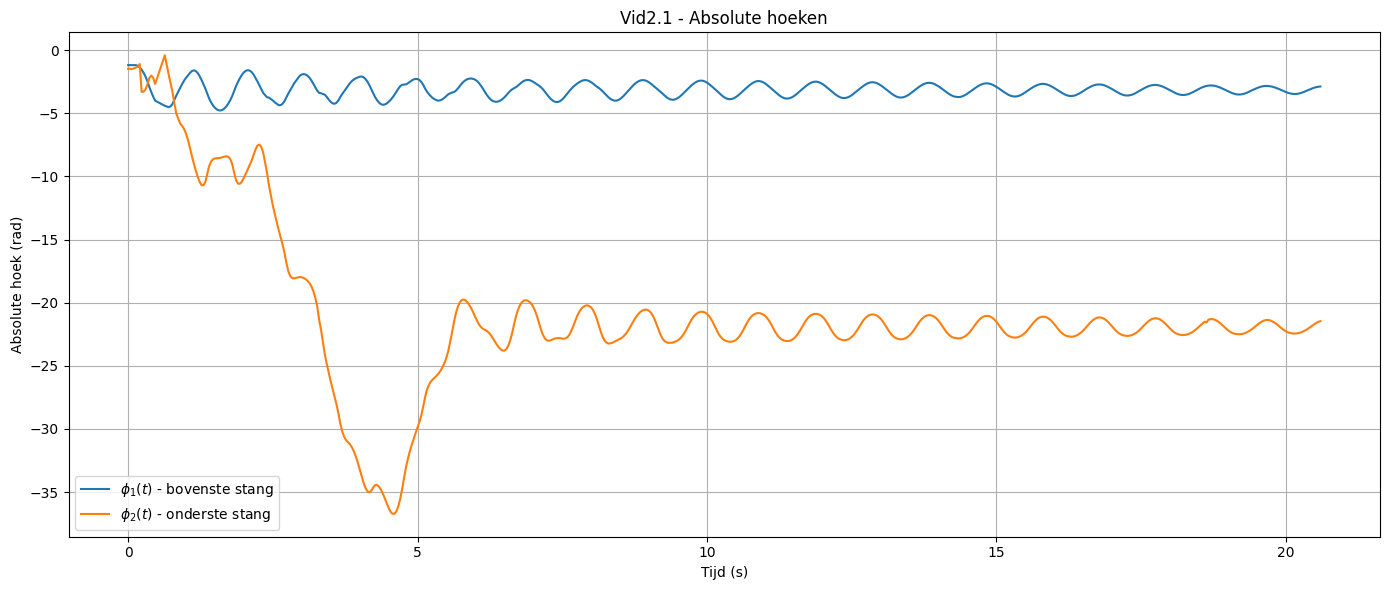

Vid2.1: 603 gezamenlijke geldige frames van 619 groene en 619 rode rijen.
Tijdsinterval: 0.000–20.600 s
Vid2.1:
  phi1 begin: -67.83°
  phi1 einde: -164.78°
  phi2 begin: -84.35°
  phi2 einde: -1229.83°
  phi1 eindrichting: 195.22°
  phi2 eindrichting: 210.17°


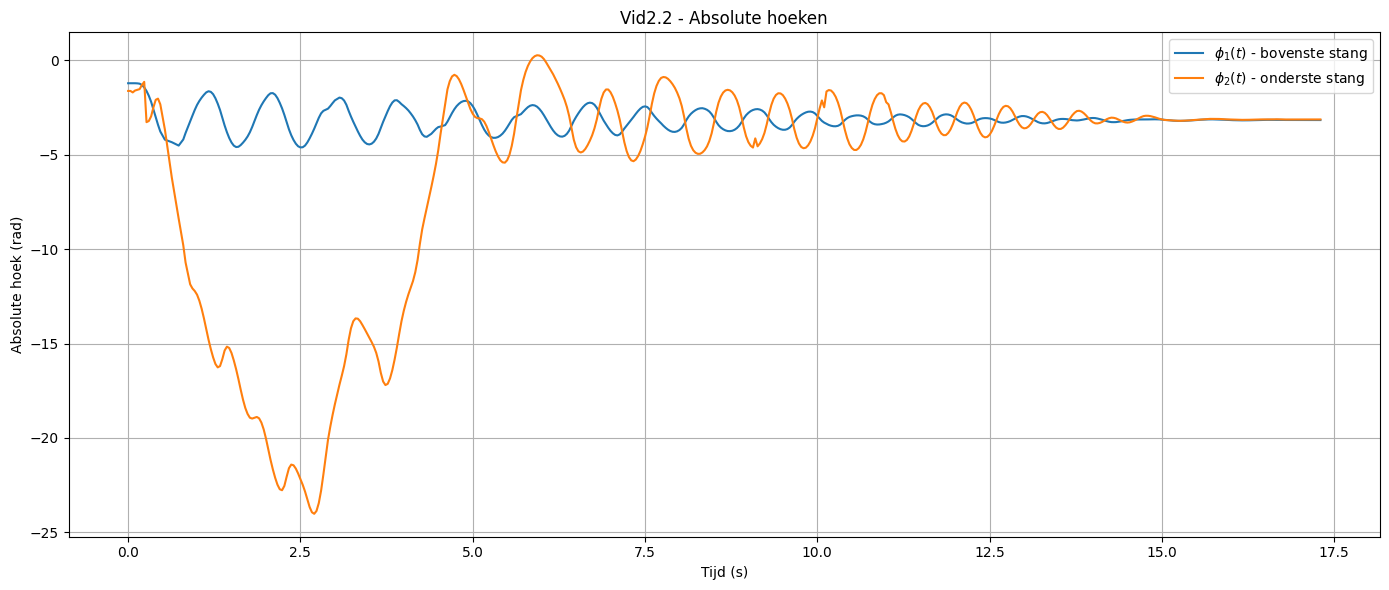

Vid2.2: 506 gezamenlijke geldige frames van 520 groene en 520 rode rijen.
Tijdsinterval: 0.000–17.300 s
Vid2.2:
  phi1 begin: -69.06°
  phi1 einde: -180.81°
  phi2 begin: -92.45°
  phi2 einde: -179.01°
  phi1 eindrichting: 179.19°
  phi2 eindrichting: 180.99°


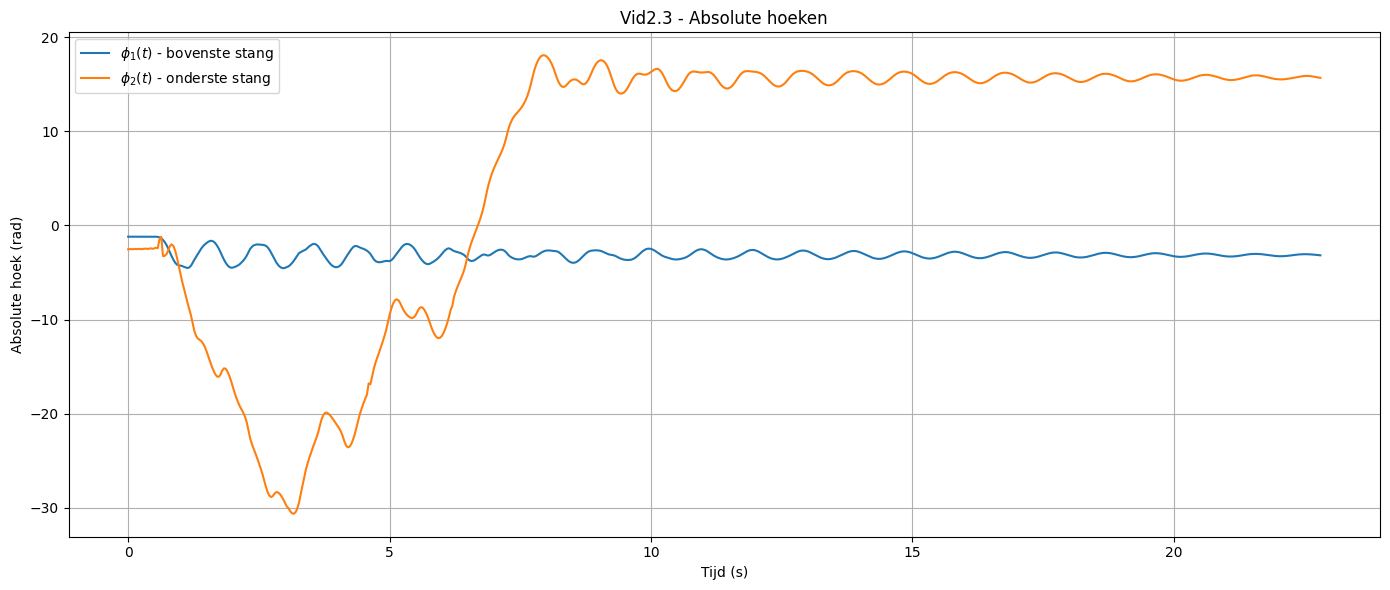

Vid2.3: 674 gezamenlijke geldige frames van 685 groene en 685 rode rijen.
Tijdsinterval: 0.000–22.808 s
Vid2.3:
  phi1 begin: -68.41°
  phi1 einde: -181.96°
  phi2 begin: -145.22°
  phi2 einde: 898.76°
  phi1 eindrichting: 178.04°
  phi2 eindrichting: 178.76°


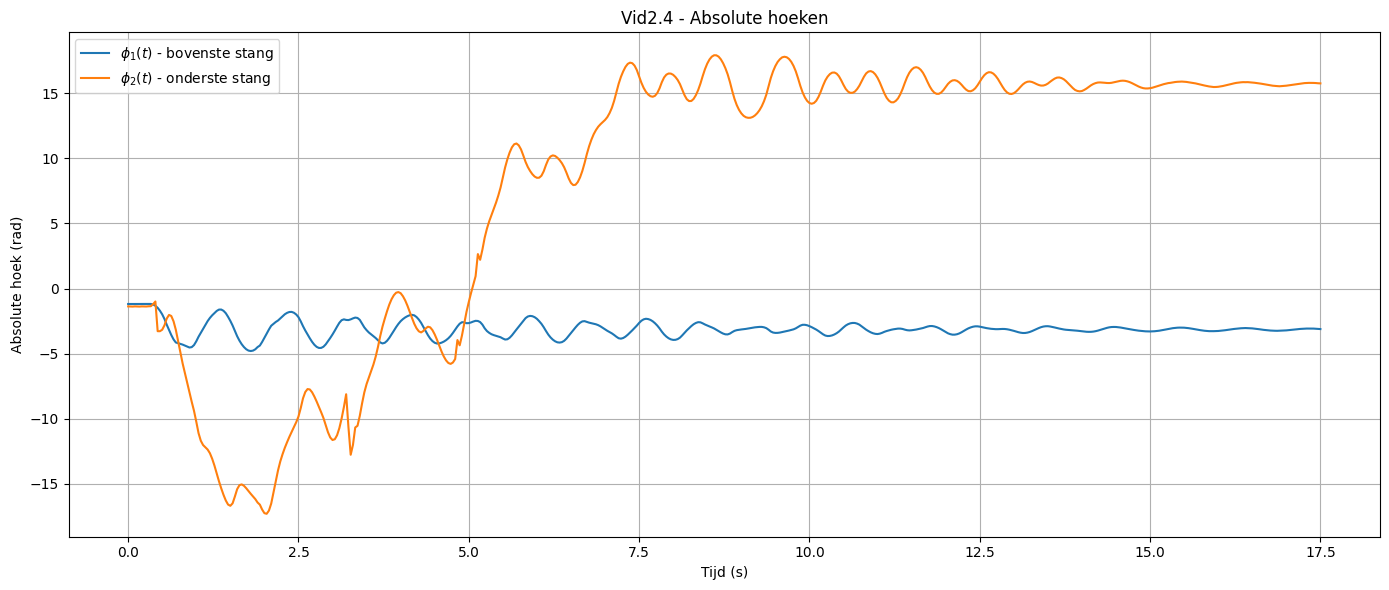

Vid2.4: 520 gezamenlijke geldige frames van 526 groene en 526 rode rijen.
Tijdsinterval: 0.000–17.500 s
Vid2.4:
  phi1 begin: -67.92°
  phi1 einde: -178.38°
  phi2 begin: -78.53°
  phi2 einde: 903.22°
  phi1 eindrichting: 181.62°
  phi2 eindrichting: 183.22°


In [3]:

# ==========================================
# 6. ABSOLUTE HOEKEN BEREKENEN EN PLOTTEN
# Nieuwe codecel: bestaande code blijft intact
# ==========================================

L1 = 0.204  # Lengte bovenste slinger (m)


def plot_angles(file_green, file_red, title):

    # Groene stip: bovenste massa
    green = pd.read_csv(file_green).rename(
        columns={"x": "x_green", "y": "y_green"}
    )

    # Rode stip: onderste massa
    red = pd.read_csv(file_red).rename(
        columns={"x": "x_red", "y": "y_red"}
    )

    # Alleen de kolommen gebruiken die we nodig hebben
    green = green[["time_s", "x_green", "y_green"]]
    red = red[["time_s", "x_red", "y_red"]]

    # Tijdstippen numeriek maken voor de zekerheid
    for column in ["time_s", "x_green", "y_green"]:
        green[column] = pd.to_numeric(
            green[column], errors="coerce"
        )

    for column in ["time_s", "x_red", "y_red"]:
        red[column] = pd.to_numeric(
            red[column], errors="coerce"
        )

    # Ongeldige tijdstippen verwijderen
    green = green.dropna(subset=["time_s"])
    red = red.dropna(subset=["time_s"])

    # Beide bestanden koppelen op hetzelfde tijdstip
    data = pd.merge(
        green,
        red,
        on="time_s",
        how="inner",
        validate="one_to_one"
    )

    # Ontbrekende of oneindige coördinaten verwijderen
    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(
        subset=["x_green", "y_green", "x_red", "y_red"]
    )

    # Op tijd sorteren
    data = data.sort_values("time_s").reset_index(drop=True)

    if len(data) < 3:
        print(
            f"{title}: te weinig gezamenlijke geldige frames "
            f"({len(data)})."
        )
        return

    # Tijdstippen en coördinaten uitlezen
    t = data["time_s"].to_numpy()

    x_green = data["x_green"].to_numpy()
    y_green = -data["y_green"].to_numpy()

    x_red = data["x_red"].to_numpy()
    y_red = -data["y_red"].to_numpy()

    # ==========================================
    # DRAAIPUNT BEPALEN MET DE GROENE STIP
    # ==========================================

    circle_data = np.concatenate([x_green, y_green])
    target = np.zeros(len(x_green))

    popt, _ = curve_fit(circlefit, circle_data, target)
    x_0, y_0, R = popt

    # Pixels naar meters omzetten
    m_per_px = L1 / abs(R)

    # ==========================================
    # COÖRDINATEN RELATIEF AAN HET DRAAIPUNT
    # ==========================================

    # Bovenste massa ten opzichte van het draaipunt
    x1 = (x_green - x_0) * m_per_px
    y1 = (y_green - y_0) * m_per_px

    # Onderste massa ten opzichte van hetzelfde draaipunt
    x2 = (x_red - x_0) * m_per_px
    y2 = (y_red - y_0) * m_per_px

    # ==========================================
    # ABSOLUTE HOEKEN BEREKENEN
    # Hoeken gemeten vanaf de neerwaartse verticaal
    # ==========================================

    # Hoek van de bovenste stang
    phi1 = np.arctan2(x1, y1)

    # Hoek van de onderste stang
    phi2 = np.arctan2(x2 - x1, y2 - y1)

    # Hoeken doorlopend maken (geen sprongen van 2*pi)
    phi1 = np.unwrap(phi1)
    phi2 = np.unwrap(phi2)

    # ==========================================
    # HOEKEN PLOTTEN VÓÓR DIFFERENTIATIE
    # ==========================================

    plt.figure(figsize=(14, 6))

    plt.plot(
        t,
        phi1,
        label=r"$\phi_1(t)$ - bovenste stang"
    )

    plt.plot(
        t,
        phi2,
        label=r"$\phi_2(t)$ - onderste stang"
    )

    plt.xlabel("Tijd (s)")
    plt.ylabel("Absolute hoek (rad)")
    plt.title(f"{title} - Absolute hoeken")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(
        f"{title}: {len(t)} gezamenlijke geldige frames "
        f"van {len(green)} groene en {len(red)} rode rijen."
    )

    print(
        f"Tijdsinterval: {t[0]:.3f}–{t[-1]:.3f} s"
    )
    print(f"{title}:")
    print(f"  phi1 begin: {np.degrees(phi1[0]):.2f}°")
    print(f"  phi1 einde: {np.degrees(phi1[-1]):.2f}°")
    print(f"  phi2 begin: {np.degrees(phi2[0]):.2f}°")
    print(f"  phi2 einde: {np.degrees(phi2[-1]):.2f}°")

    print(f"  phi1 eindrichting: {np.degrees(phi1[-1]) % 360:.2f}°")
    print(f"  phi2 eindrichting: {np.degrees(phi2[-1]) % 360:.2f}°")


# ==========================================
# 7. SET 3: ZES VIDEO'S
# ==========================================

for green_file, red_file in zip(filelist_green, filelist_red):
    plot_angles(
        green_file,
        red_file,
        green_file.split("_")[0]
    )


# ==========================================
# 8. SET 2: VIJF VIDEO'S
# ==========================================

for green_file, red_file in zip(filelist_green2, filelist_red2):
    plot_angles(
        green_file,
        red_file,
        green_file.split("_")[0]
    )


L1 = 0.2040 m, L2 = 0.1602 m
m1 = 0.5406 kg, m2 = 0.2001 kg


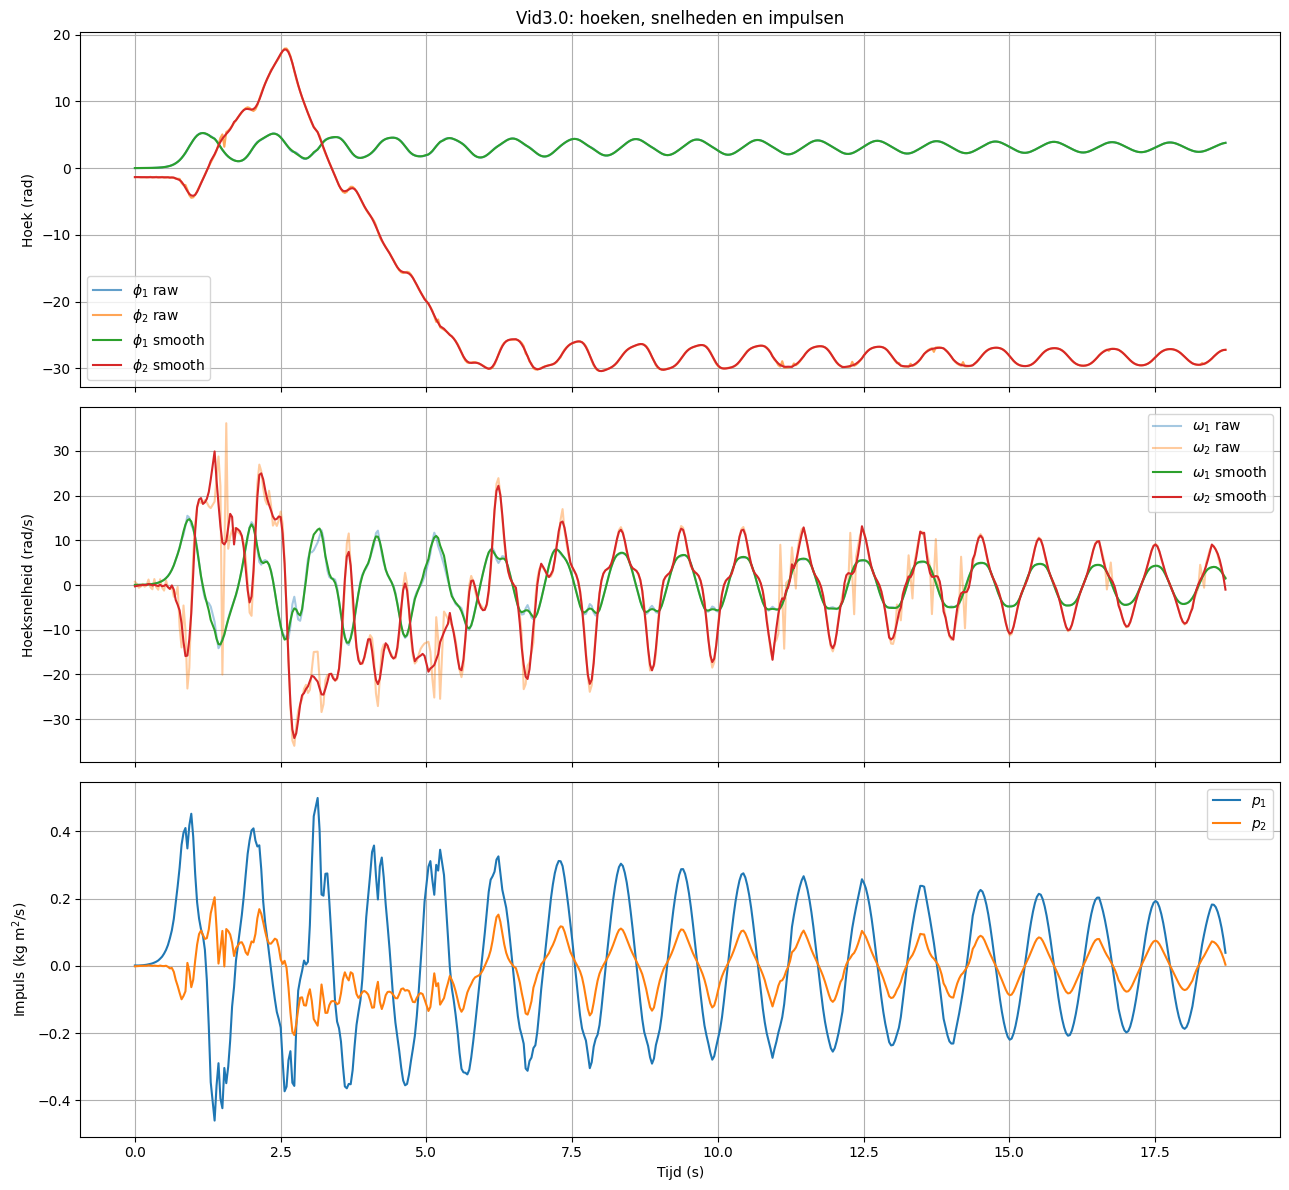


Vid3.0
Geldige frames: 558
Tijdsinterval: 0.000–18.710 s
Mediane tijdstap: 0.03335 s
Kalibratie: 0.000678907 m/pixel
CSV opgeslagen als: Vid3.0_canonical_coordinates.csv


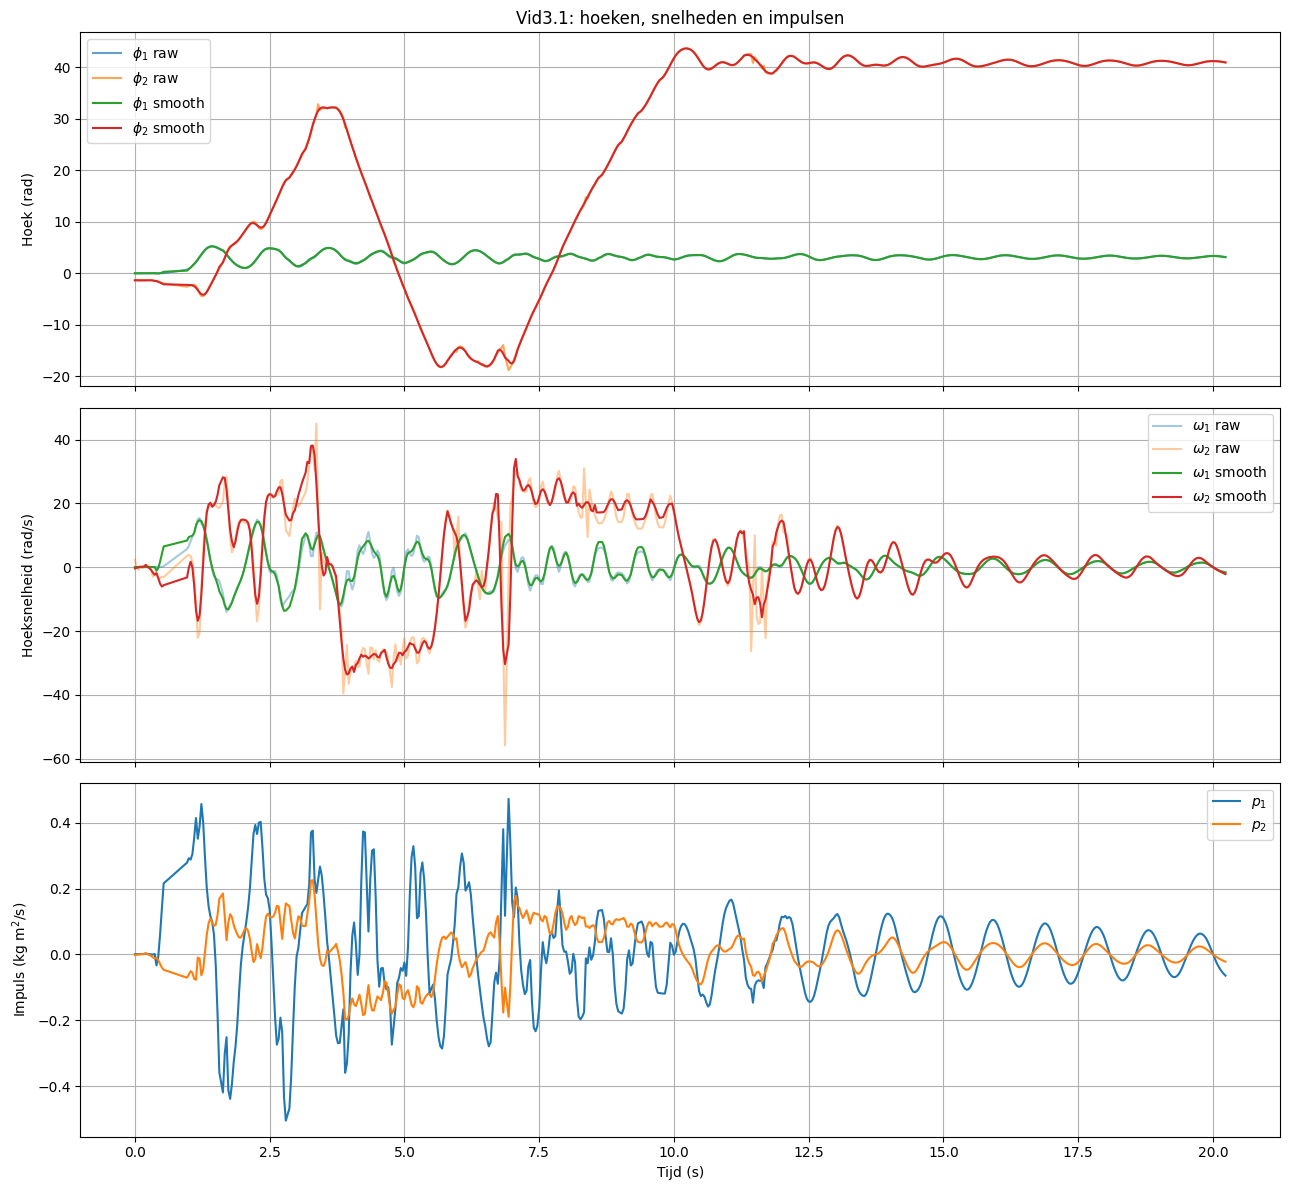


Vid3.1
Geldige frames: 588
Tijdsinterval: 0.000–20.233 s
Mediane tijdstap: 0.03333 s
Kalibratie: 0.000679061 m/pixel
CSV opgeslagen als: Vid3.1_canonical_coordinates.csv


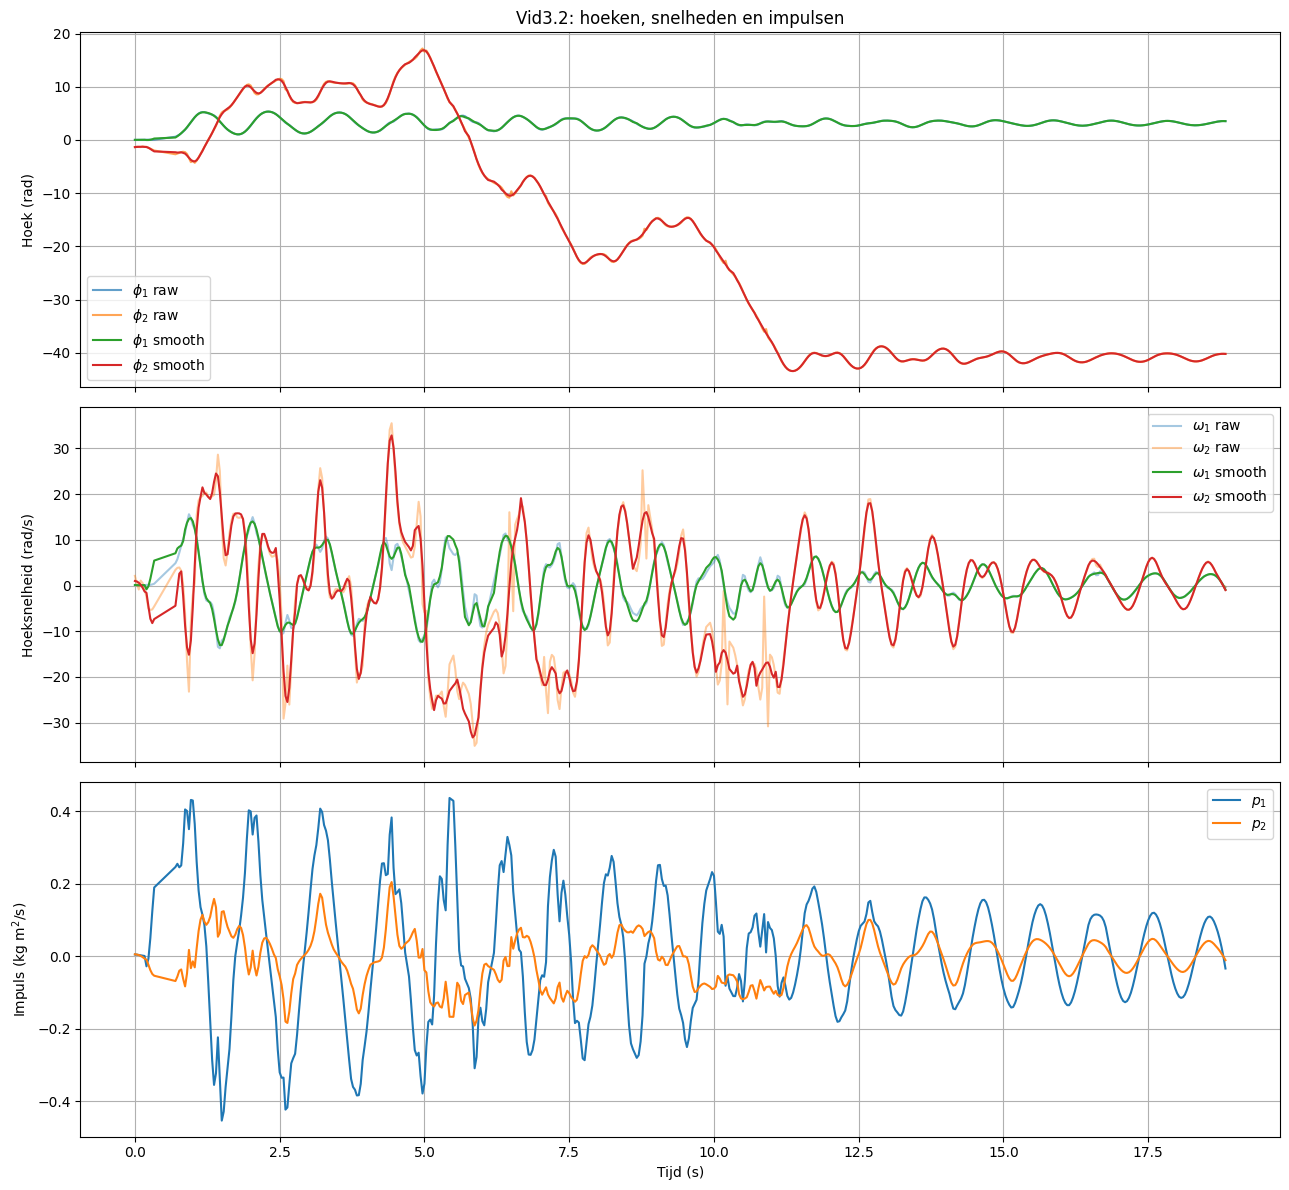


Vid3.2
Geldige frames: 548
Tijdsinterval: 0.000–18.833 s
Mediane tijdstap: 0.03333 s
Kalibratie: 0.000678635 m/pixel
CSV opgeslagen als: Vid3.2_canonical_coordinates.csv


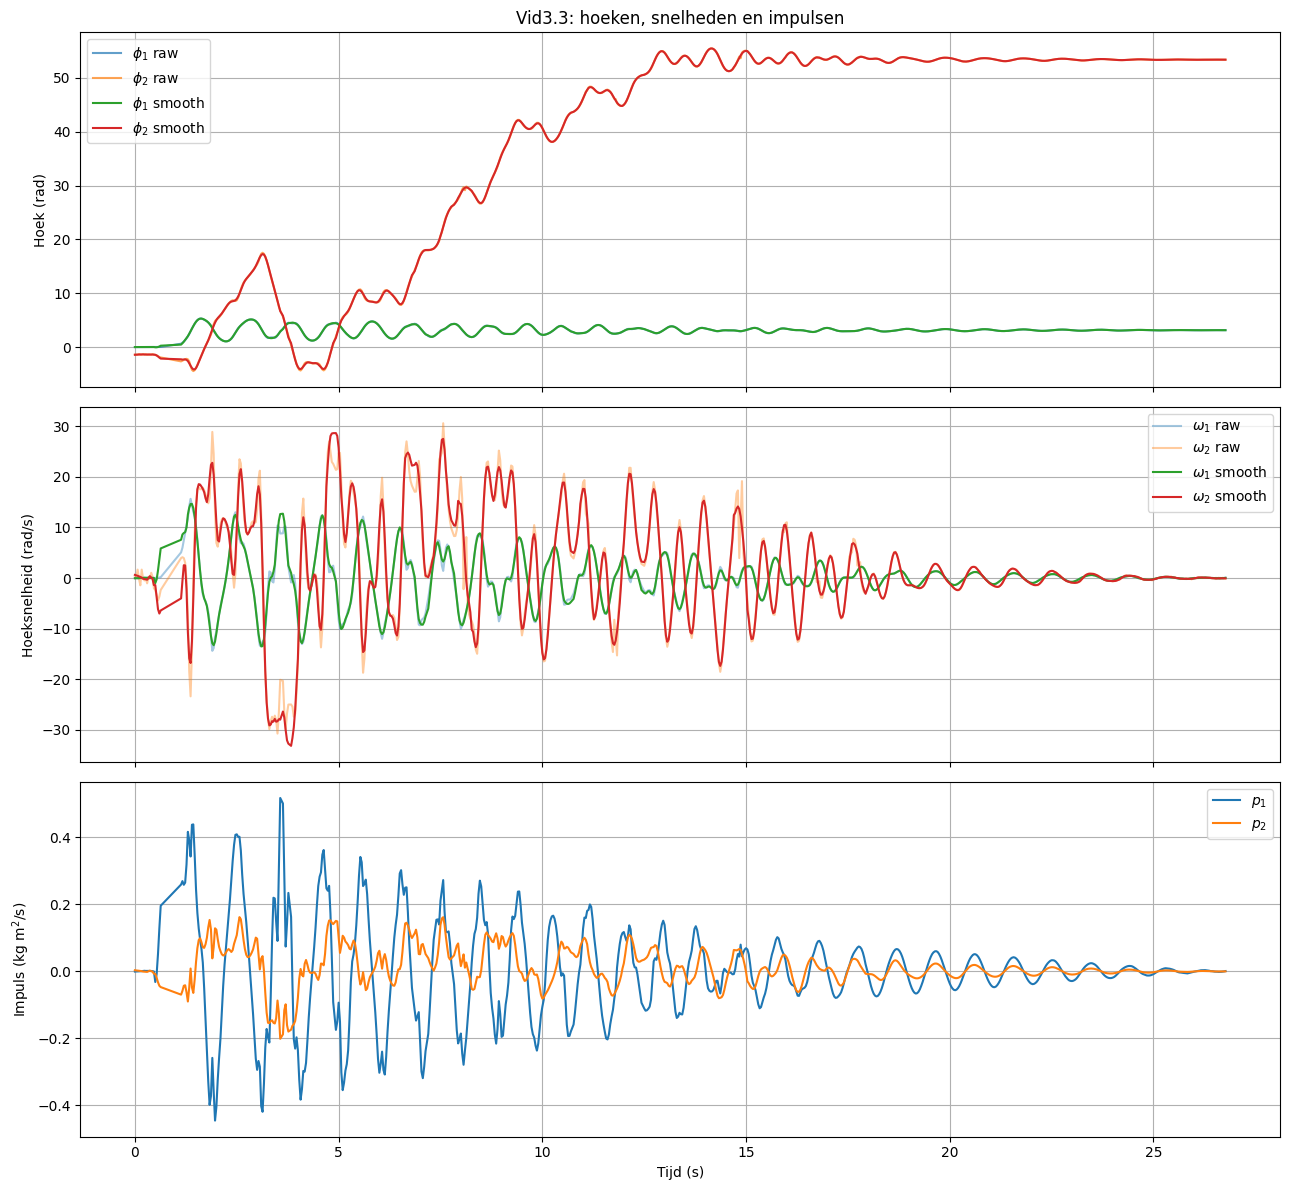


Vid3.3
Geldige frames: 782
Tijdsinterval: 0.000–26.767 s
Mediane tijdstap: 0.03333 s
Kalibratie: 0.000679069 m/pixel
CSV opgeslagen als: Vid3.3_canonical_coordinates.csv


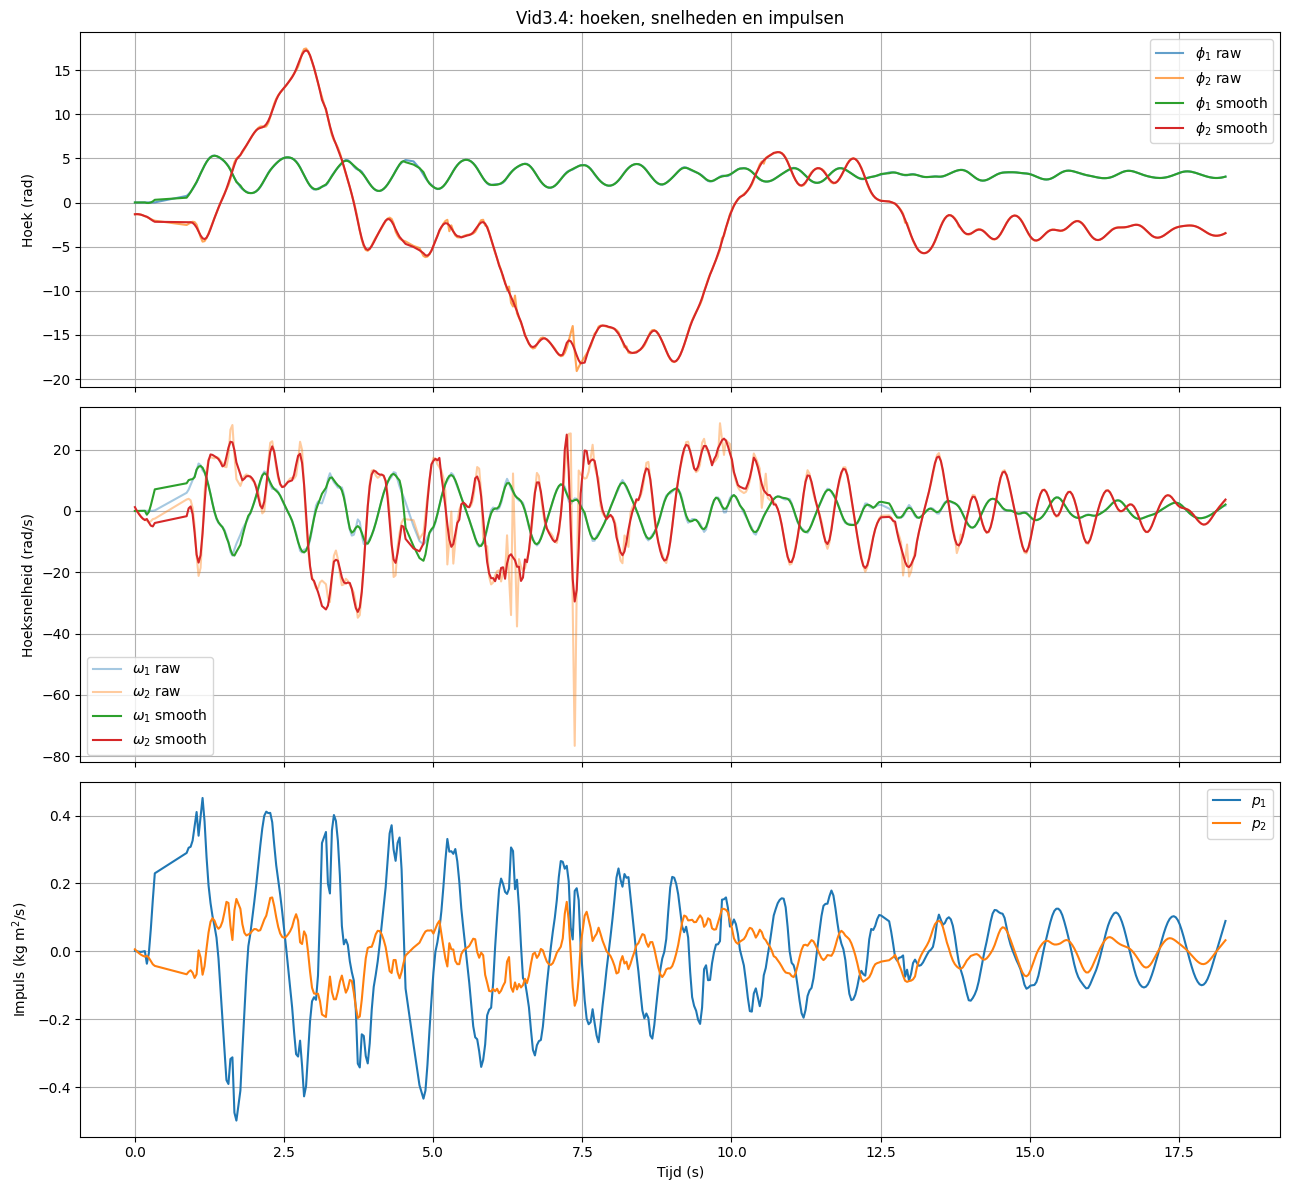


Vid3.4
Geldige frames: 521
Tijdsinterval: 0.000–18.280 s
Mediane tijdstap: 0.03336 s
Kalibratie: 0.000678414 m/pixel
CSV opgeslagen als: Vid3.4_canonical_coordinates.csv


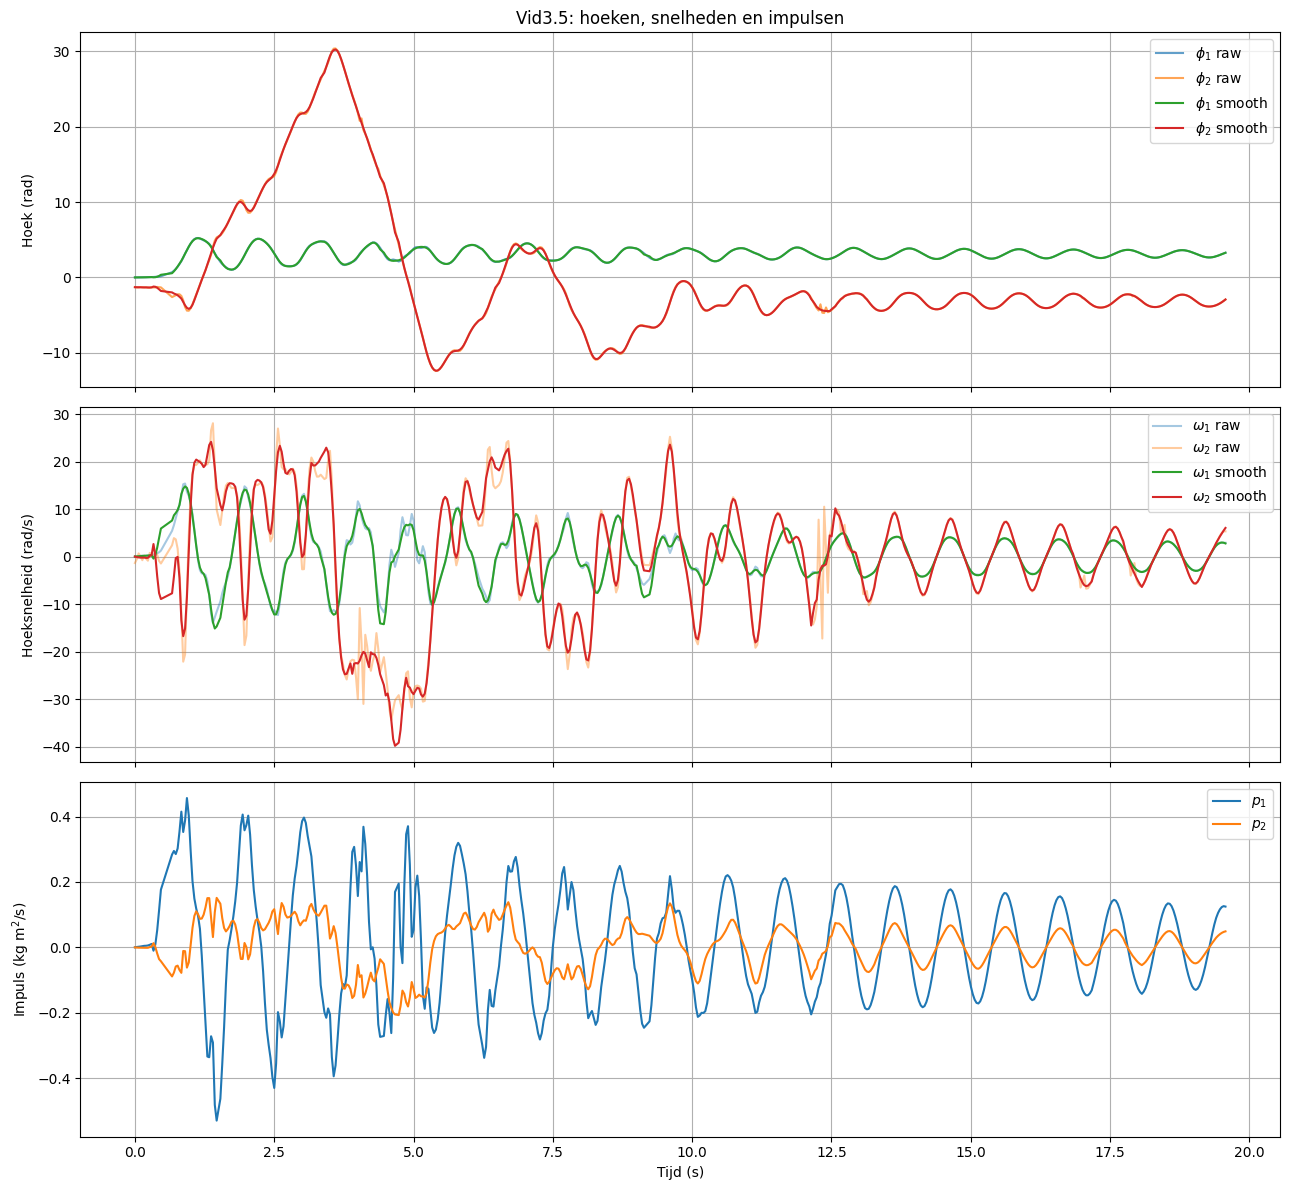


Vid3.5
Geldige frames: 575
Tijdsinterval: 0.000–19.572 s
Mediane tijdstap: 0.03334 s
Kalibratie: 0.000679406 m/pixel
CSV opgeslagen als: Vid3.5_canonical_coordinates.csv


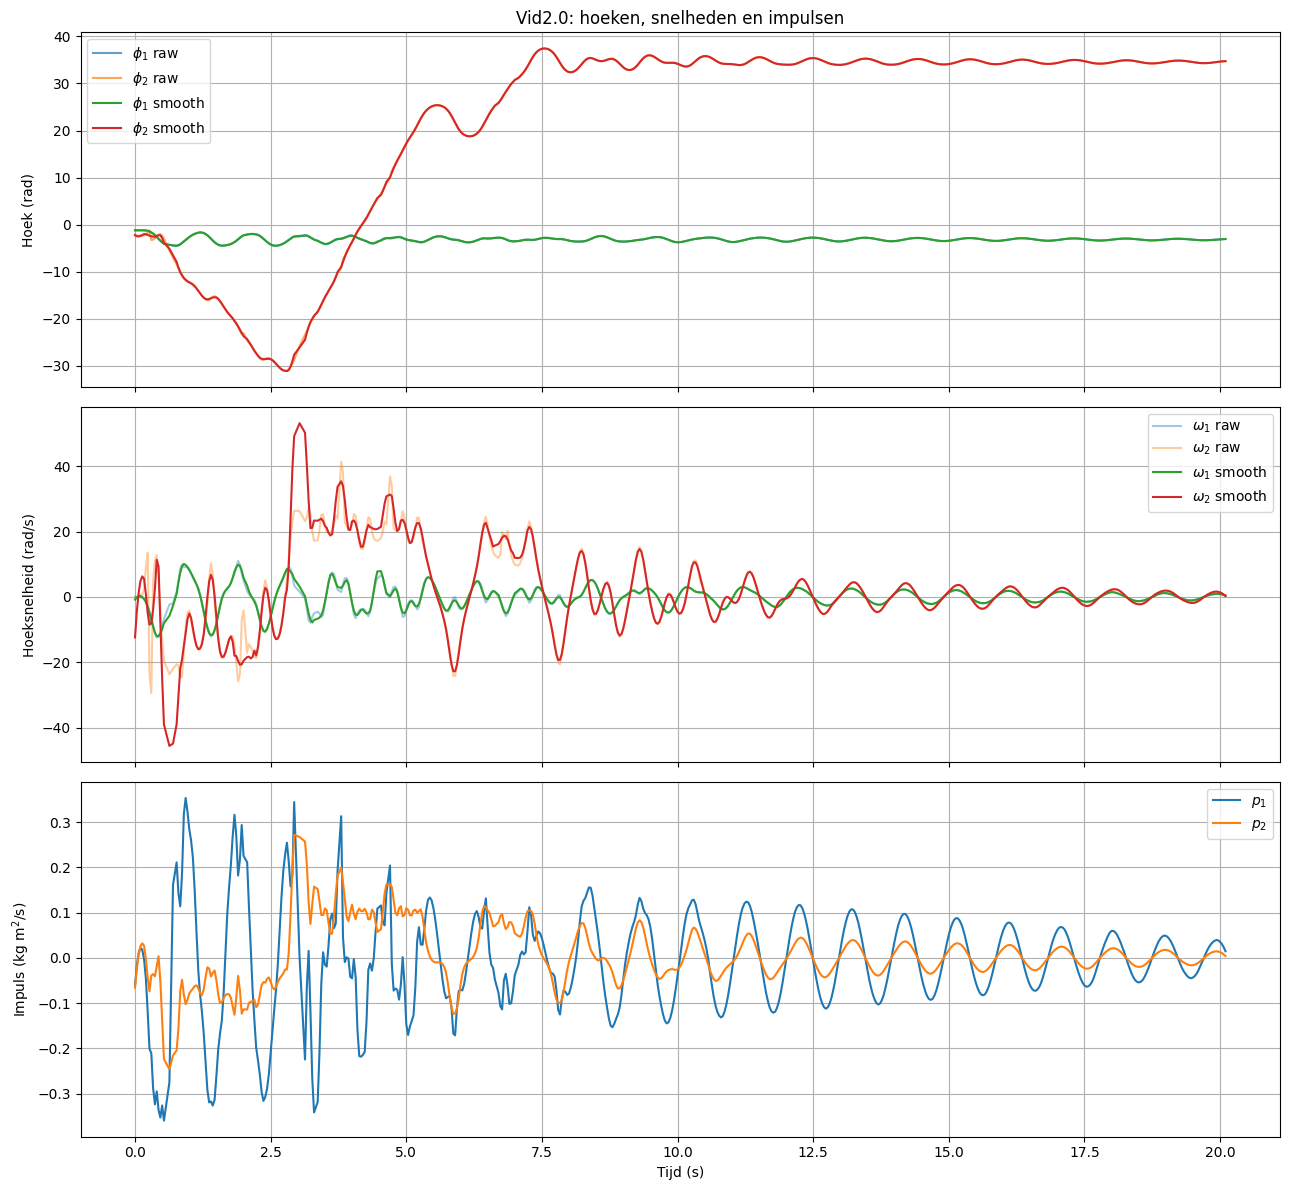


Vid2.0
Geldige frames: 589
Tijdsinterval: 0.000–20.100 s
Mediane tijdstap: 0.03333 s
Kalibratie: 0.000674942 m/pixel
CSV opgeslagen als: Vid2.0_canonical_coordinates.csv


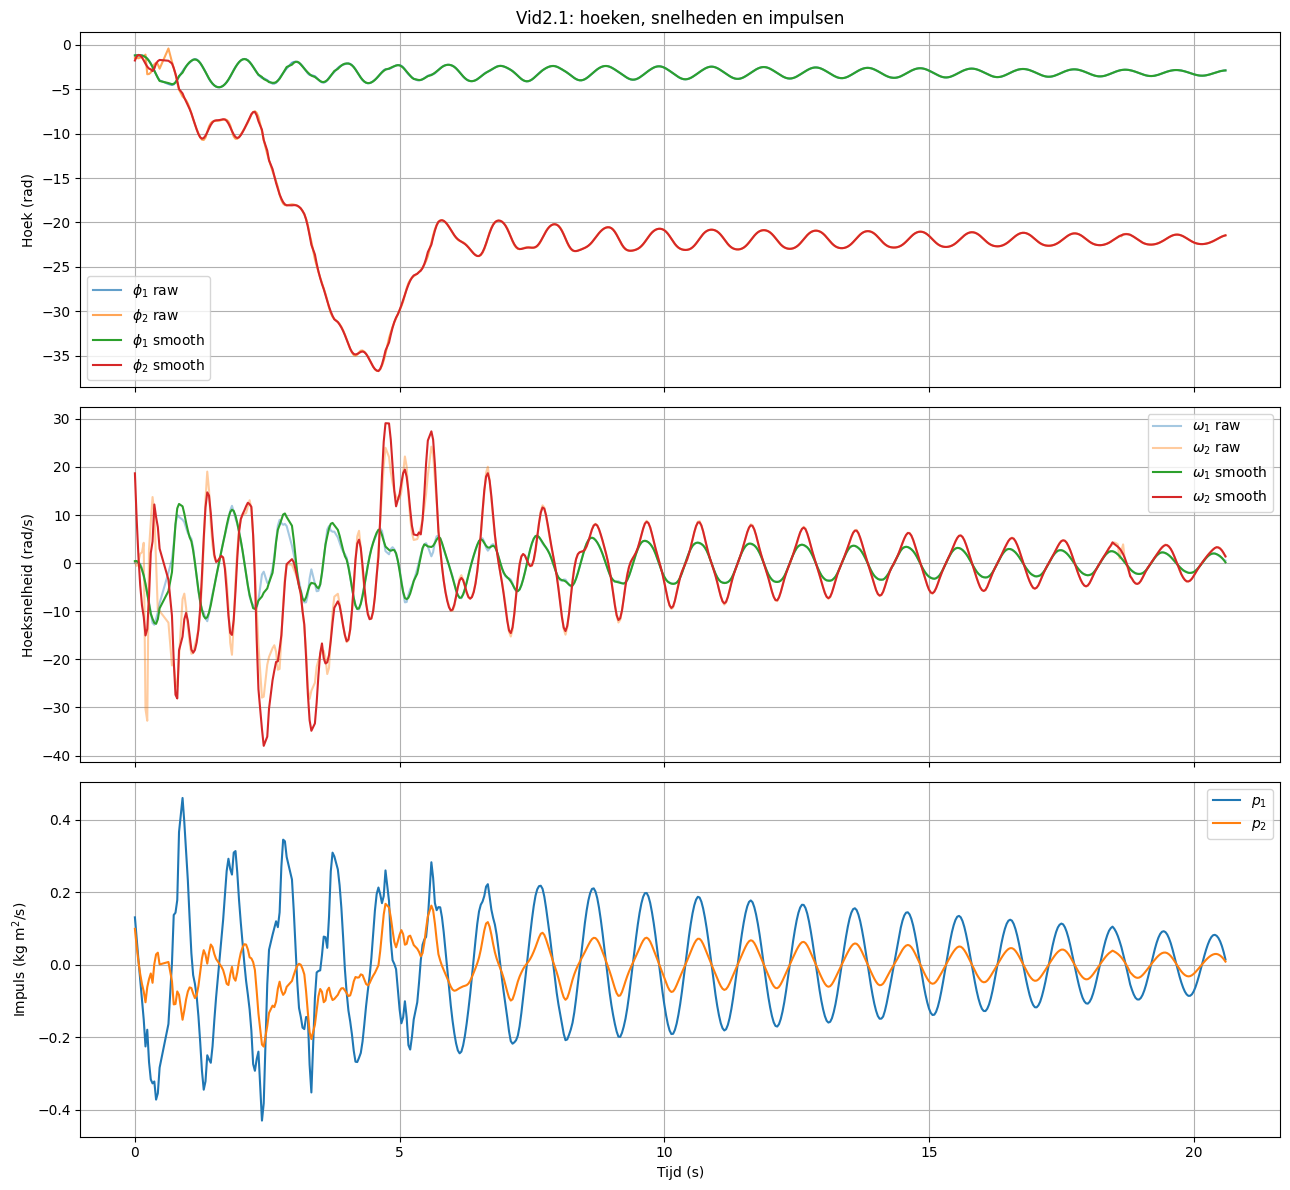


Vid2.1
Geldige frames: 603
Tijdsinterval: 0.000–20.600 s
Mediane tijdstap: 0.03333 s
Kalibratie: 0.000675669 m/pixel
CSV opgeslagen als: Vid2.1_canonical_coordinates.csv


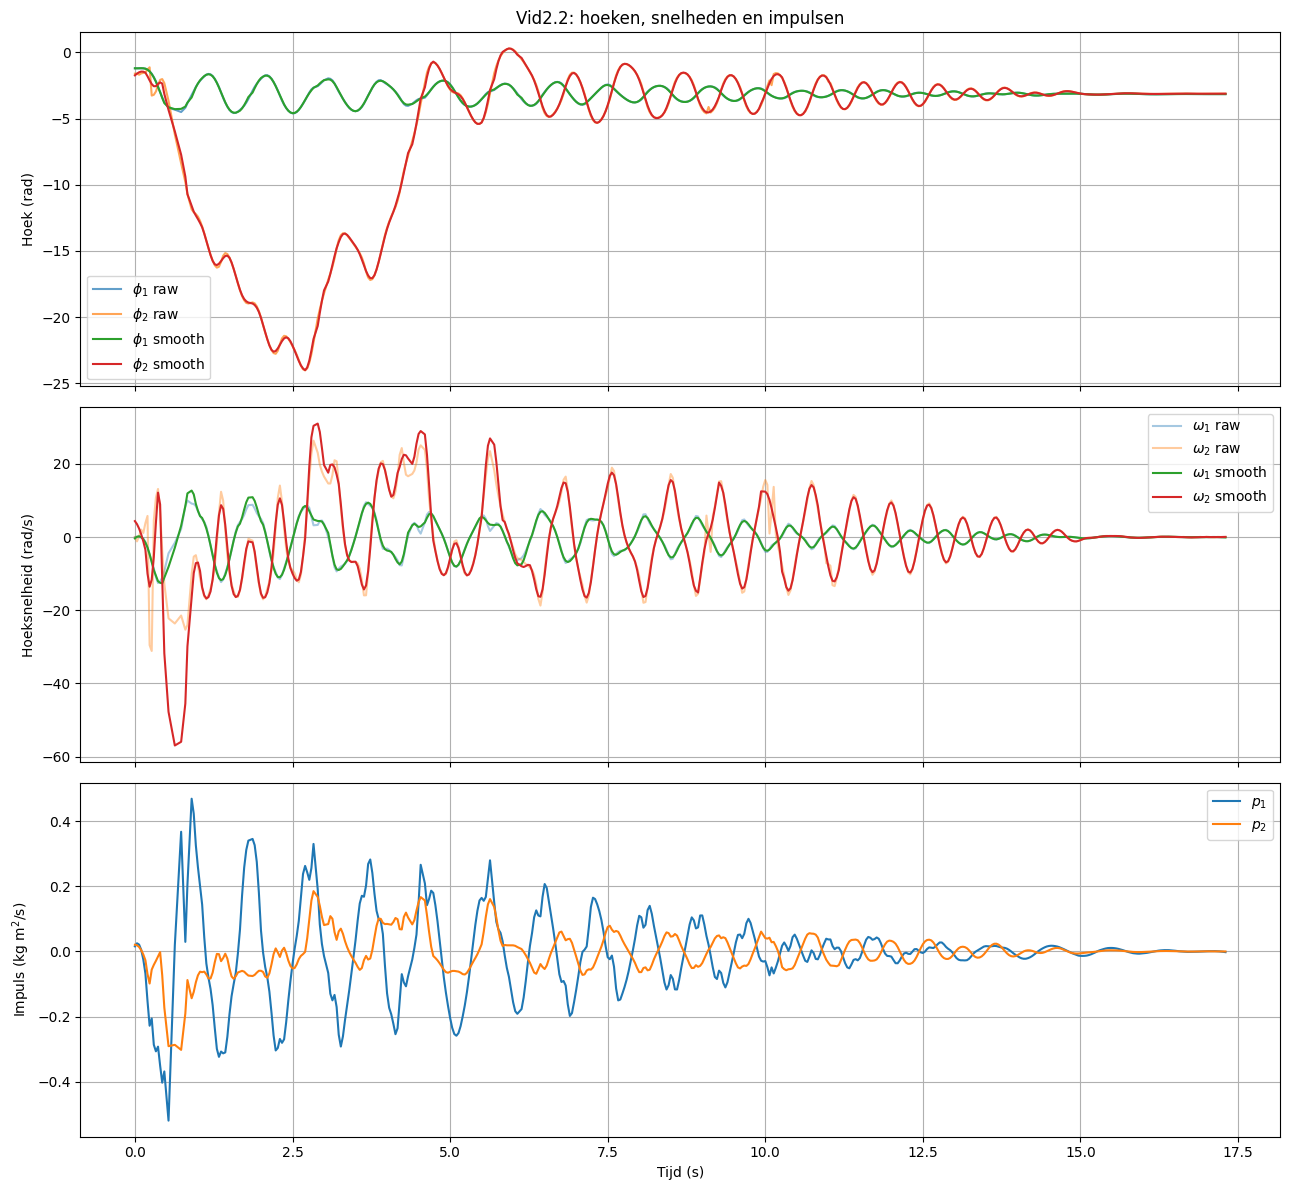


Vid2.2
Geldige frames: 506
Tijdsinterval: 0.000–17.300 s
Mediane tijdstap: 0.03333 s
Kalibratie: 0.000675498 m/pixel
CSV opgeslagen als: Vid2.2_canonical_coordinates.csv


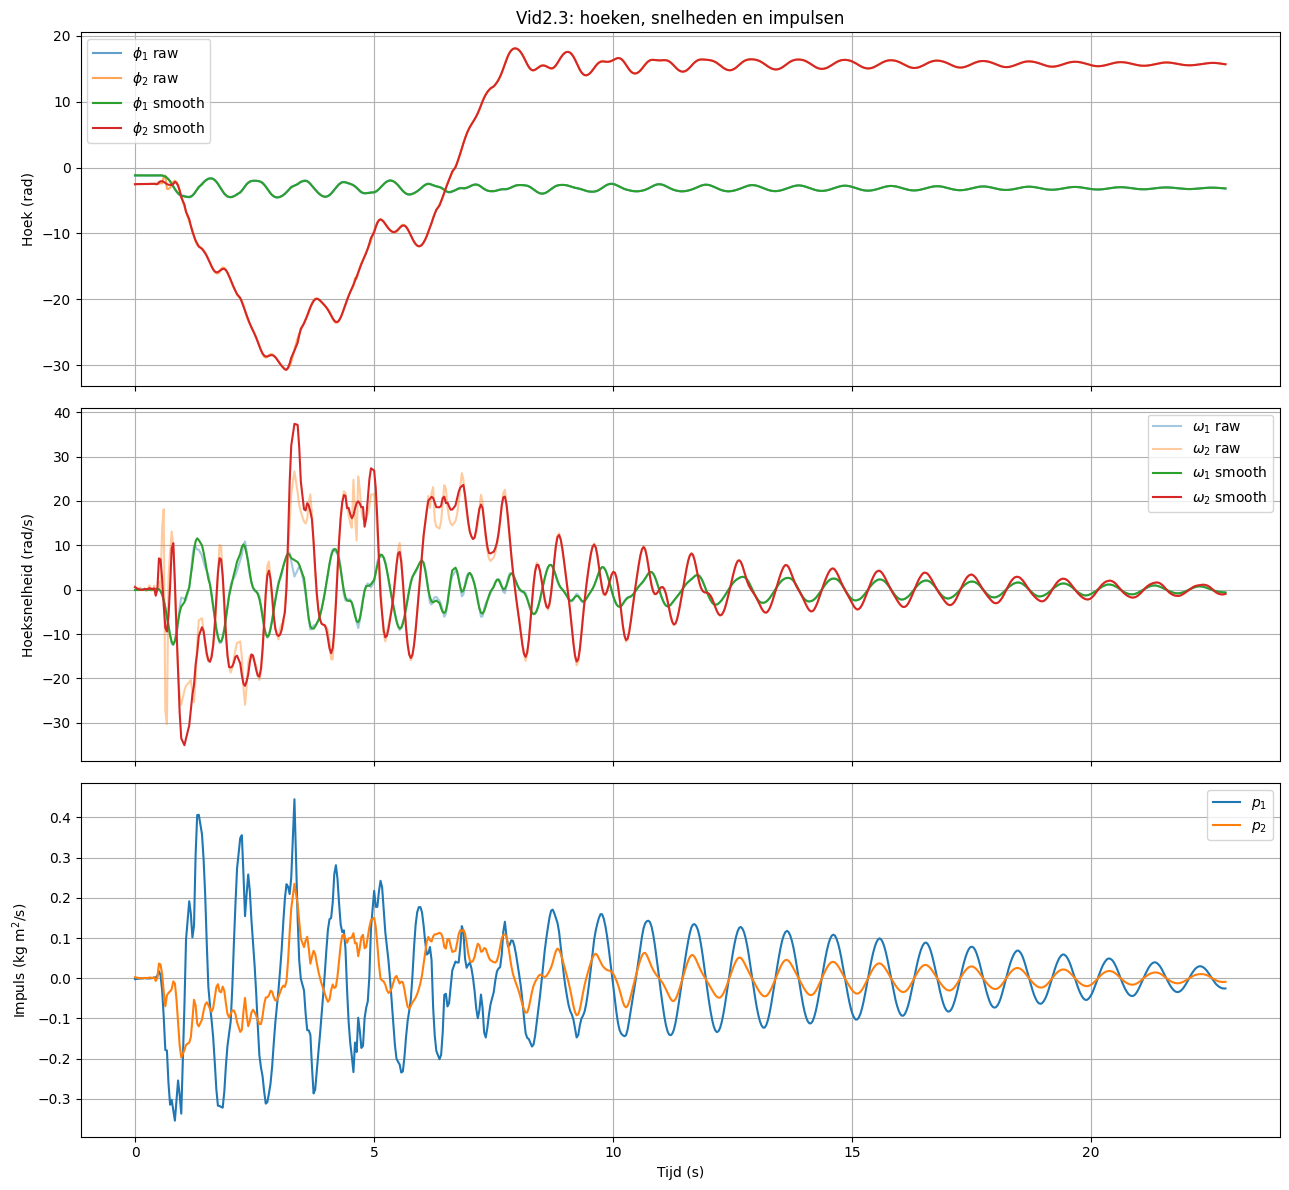


Vid2.3
Geldige frames: 674
Tijdsinterval: 0.000–22.808 s
Mediane tijdstap: 0.03335 s
Kalibratie: 0.000675309 m/pixel
CSV opgeslagen als: Vid2.3_canonical_coordinates.csv


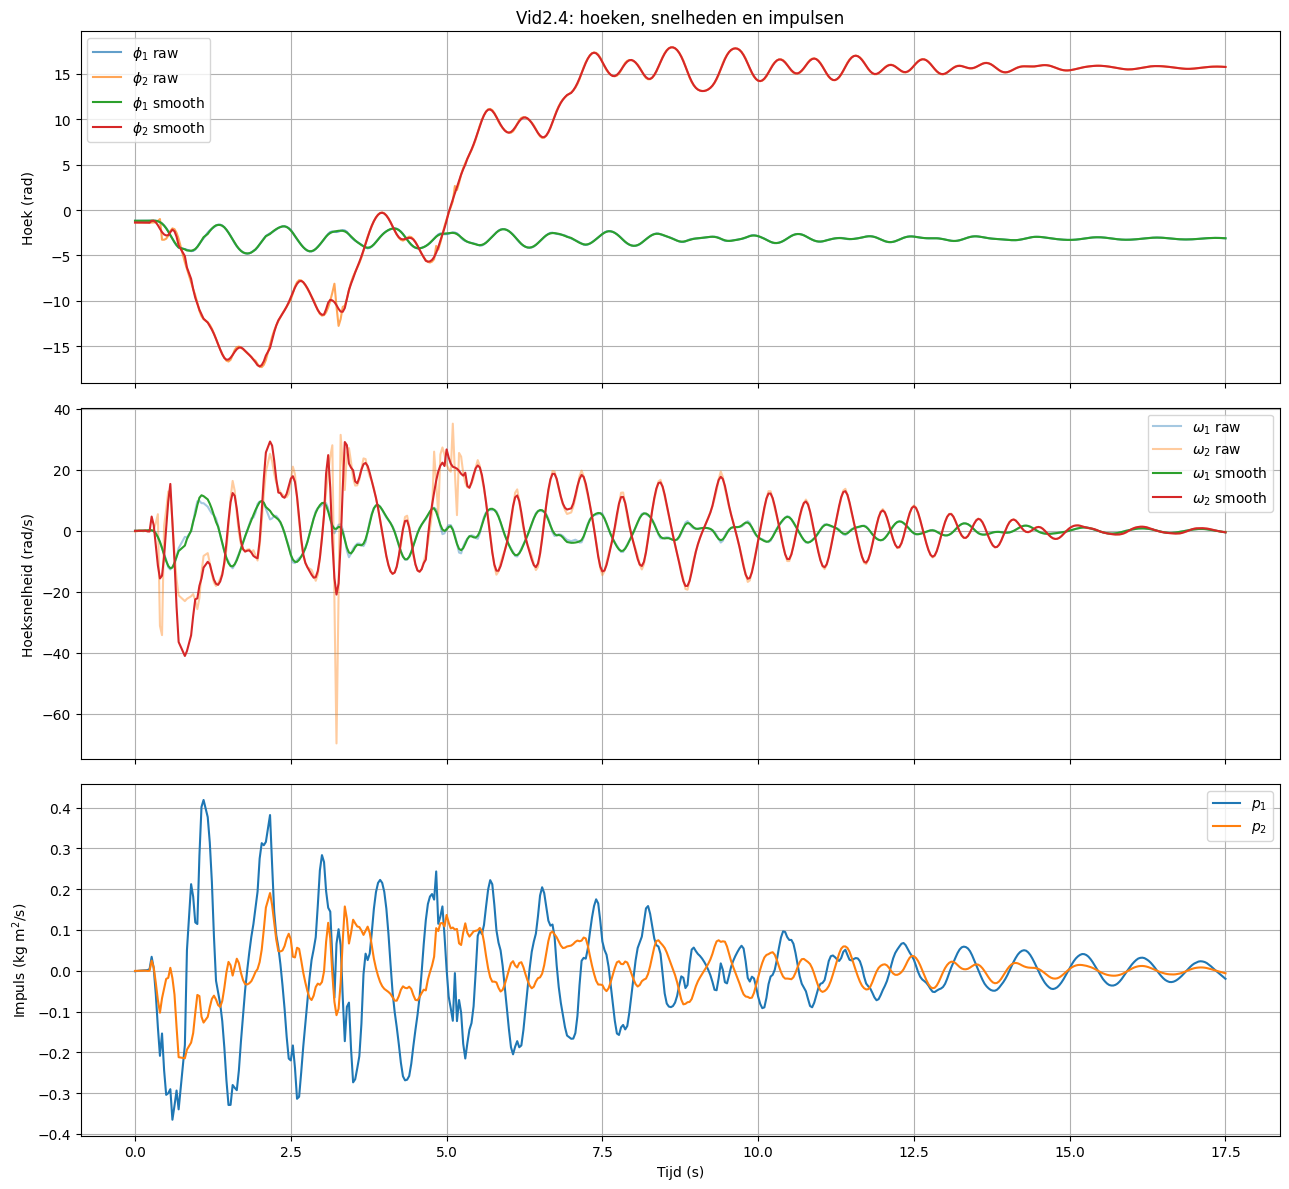


Vid2.4
Geldige frames: 520
Tijdsinterval: 0.000–17.500 s
Mediane tijdstap: 0.03333 s
Kalibratie: 0.000676039 m/pixel
CSV opgeslagen als: Vid2.4_canonical_coordinates.csv


In [4]:

# ==========================================
# 7. HOEKSNELHEDEN, IMPULSEN EN CSV-EXPORT
# Nieuwe codecel: bestaande code blijft intact
# ==========================================

import os
from scipy.signal import savgol_filter

# Gemeten systeemparameters
L1 = L1_cm / 100  # meter
L2 = L2_cm / 100  # meter

print(f"L1 = {L1:.4f} m, L2 = {L2:.4f} m")
print(f"m1 = {m1:.4f} kg, m2 = {m2:.4f} kg")


def calculate_canonical_coordinates(file_green, file_red, title):

    # 1. Bestanden inlezen
    green = pd.read_csv(file_green).rename(
        columns={"x": "x_green", "y": "y_green"}
    )
    red = pd.read_csv(file_red).rename(
        columns={"x": "x_red", "y": "y_red"}
    )

    green = green[["time_s", "x_green", "y_green"]]
    red = red[["time_s", "x_red", "y_red"]]

    # Waarden numeriek maken
    for col in ["time_s", "x_green", "y_green"]:
        green[col] = pd.to_numeric(green[col], errors="coerce")

    for col in ["time_s", "x_red", "y_red"]:
        red[col] = pd.to_numeric(red[col], errors="coerce")

    # Koppelen op tijdstip, zodat beide stippen bij hetzelfde frame horen
    data = pd.merge(
        green.dropna(subset=["time_s"]),
        red.dropna(subset=["time_s"]),
        on="time_s",
        how="inner",
        validate="one_to_one"
    )

    # Ongeldige coördinaten verwijderen
    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(
        subset=["x_green", "y_green", "x_red", "y_red"]
    )
    data = data.sort_values("time_s").reset_index(drop=True)

    if len(data) < 11:
        print(f"{title}: te weinig geldige frames.")
        return None

    # 2. Tijd en coördinaten uitlezen
    t = data["time_s"].to_numpy()

    x_green = data["x_green"].to_numpy()
    y_green = -data["y_green"].to_numpy()

    x_red = data["x_red"].to_numpy()
    y_red = -data["y_red"].to_numpy()

    # Controleer of de tijdstippen strikt oplopen
    dt = np.diff(t)

    if np.any(dt <= 0):
        print(f"{title}: tijdstippen zijn niet strikt oplopend.")
        return None

    dt_median = np.median(dt)

    # 3. Draaipunt bepalen via de cirkelfit van de groene stip
    circle_data = np.concatenate([x_green, y_green])
    target = np.zeros(len(x_green))

    popt, _ = curve_fit(circlefit, circle_data, target)
    x_0, y_0, R = popt

    # Pixelcoördinaten omzetten naar meters
    m_per_px = L1 / abs(R)

    # Posities ten opzichte van het draaipunt
    x1 = (x_green - x_0) * m_per_px
    y1 = (y_green - y_0) * m_per_px

    x2 = (x_red - x_0) * m_per_px
    y2 = (y_red - y_0) * m_per_px

    # 4. Absolute hoeken berekenen en unwrap toepassen
    phi1 = np.unwrap(np.arctan2(x1, y1))
    phi2 = np.unwrap(np.arctan2(x2 - x1, y2 - y1))

    # 5. Ruwe hoeksnelheden berekenen
    omega1_raw = np.gradient(phi1, t)
    omega2_raw = np.gradient(phi2, t)

    # 6. Hoeken licht smoothen en hoeksnelheden bepalen
    # Venster: maximaal 11 frames, met een oneven aantal punten
    window = min(11, len(t) if len(t) % 2 == 1 else len(t) - 1)

    phi1_smooth = savgol_filter(phi1, window, 3)
    phi2_smooth = savgol_filter(phi2, window, 3)

    # Afgeleiden van de hoeken
    # Dit veronderstelt dat de tijdstappen ongeveer gelijk zijn
    omega1 = savgol_filter(
        phi1, window, 3, deriv=1, delta=dt_median
    )
    omega2 = savgol_filter(
        phi2, window, 3, deriv=1, delta=dt_median
    )

    # 7. Gegeneraliseerde impulsen berekenen
    delta_phi = phi1 - phi2

    p1 = (
        (m1 + m2) * L1**2 * omega1
        + m2 * L1 * L2 * omega2 * np.cos(delta_phi)
    )

    p2 = (
        m2 * L2**2 * omega2
        + m2 * L1 * L2 * omega1 * np.cos(delta_phi)
    )

    # 8. Canonieke coördinaten exporteren
    output = pd.DataFrame({
        "time_s": t,
        "phi1_rad": phi1,
        "phi2_rad": phi2,
        "omega1_raw_rad_s": omega1_raw,
        "omega2_raw_rad_s": omega2_raw,
        "omega1_rad_s": omega1,
        "omega2_rad_s": omega2,
        "p1_kg_m2_s": p1,
        "p2_kg_m2_s": p2
    })

    # CSV opslaan in dezelfde map als het groene bestand
    output_file = os.path.join(
        os.path.dirname(file_green),
        os.path.basename(file_green).split("_")[0]
        + "_canonical_coordinates.csv"
    )

    output.to_csv(output_file, index=False)

    # 9. Controleplots maken
    fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)

    # Hoeken
    axes[0].plot(t, phi1, label=r"$\phi_1$ raw", alpha=0.7)
    axes[0].plot(t, phi2, label=r"$\phi_2$ raw", alpha=0.7)
    axes[0].plot(t, phi1_smooth, label=r"$\phi_1$ smooth")
    axes[0].plot(t, phi2_smooth, label=r"$\phi_2$ smooth")
    axes[0].set_ylabel("Hoek (rad)")
    axes[0].set_title(f"{title}: hoeken, snelheden en impulsen")
    axes[0].legend()
    axes[0].grid(True)

    # Hoeksnelheden
    axes[1].plot(
        t, omega1_raw, alpha=0.4, label=r"$\omega_1$ raw"
    )
    axes[1].plot(
        t, omega2_raw, alpha=0.4, label=r"$\omega_2$ raw"
    )
    axes[1].plot(t, omega1, label=r"$\omega_1$ smooth")
    axes[1].plot(t, omega2, label=r"$\omega_2$ smooth")
    axes[1].set_ylabel("Hoeksnelheid (rad/s)")
    axes[1].legend()
    axes[1].grid(True)

    # Gegeneraliseerde impulsen
    axes[2].plot(t, p1, label=r"$p_1$")
    axes[2].plot(t, p2, label=r"$p_2$")
    axes[2].set_xlabel("Tijd (s)")
    axes[2].set_ylabel(r"Impuls (kg m$^2$/s)")
    axes[2].legend()
    axes[2].grid(True)

    plt.tight_layout()
    plt.show()

    # 10. Resultaten samenvatten
    print(f"\n{title}")
    print(f"Geldige frames: {len(t)}")
    print(f"Tijdsinterval: {t[0]:.3f}–{t[-1]:.3f} s")
    print(f"Mediane tijdstap: {dt_median:.5f} s")
    print(f"Kalibratie: {m_per_px:.6g} m/pixel")
    print(f"CSV opgeslagen als: {output_file}")

    return output


# Set 3
canonical_data = {}

for green_file, red_file in zip(filelist_green, filelist_red):
    title = os.path.basename(green_file).split("_")[0]

    canonical_data[title] = calculate_canonical_coordinates(
        green_file, red_file, title
    )

# Set 2
for green_file, red_file in zip(filelist_green2, filelist_red2):
    title = os.path.basename(green_file).split("_")[0]

    canonical_data[title] = calculate_canonical_coordinates(
        green_file, red_file, title
    )


Vid3.0: start op t = 0.2001 s, 552 samples.
Vid3.1: start op t = 0.2000 s, 582 samples.

Gebruikte normalisatieschalen:
theta1_scale = 1 rad
theta2_scale = 1 rad
p1_scale     = 0.173467 kg m^2/s
p2_scale     = 0.0724887 kg m^2/s

Beginwaarden:
Vid3.0:
  phi1 = 0.034870 rad
  phi2 = -1.370211 rad
  p1   = 3.210954e-03 kg m^2/s
  p2   = 9.609791e-05 kg m^2/s
Vid3.1:
  phi1 = 0.015030 rad
  phi2 = -1.351552 rad
  p1   = 2.671103e-03 kg m^2/s
  p2   = 3.754392e-03 kg m^2/s

Verschillen bij tau = 0:
  delta phi1 = 0.019841 rad
  delta phi2 = -0.018659 rad
  delta p1   = 5.398517e-04 kg m^2/s
  delta p2   = -3.658295e-03 kg m^2/s
  delta(0)   = 5.743197e-02


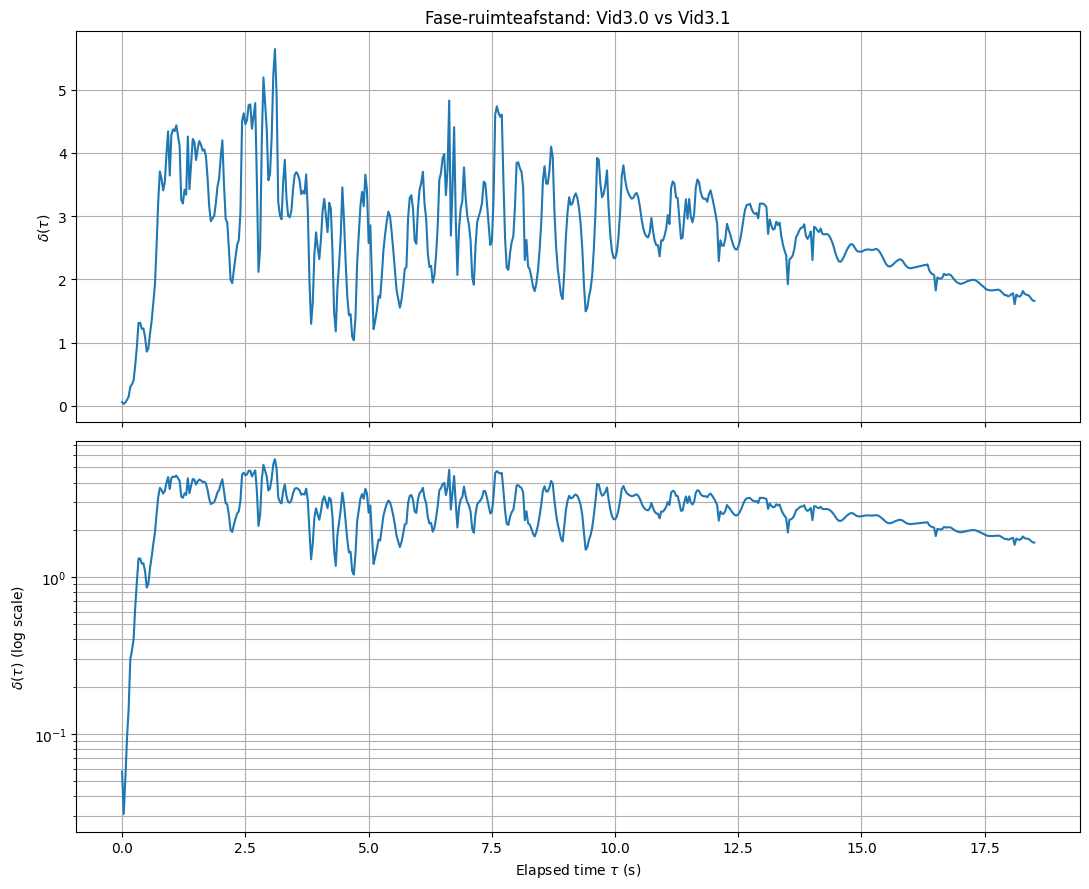

Fitinterval: 0.200–0.767 s | lambda = 3.04627 1/s | R^2 = 0.7561 | fit-extrapolatie delta(0) = 2.7456e-01


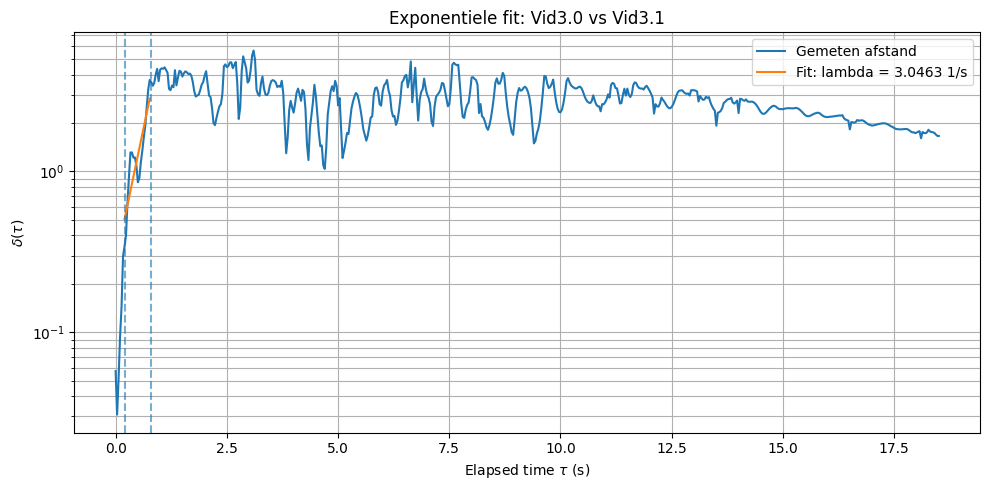


Robuustheid van lambda bij naburige intervallen:
Fitinterval: 0.200–0.767 s | lambda = 3.04627 1/s | R^2 = 0.7561 | fit-extrapolatie delta(0) = 2.7456e-01
Fitinterval: 0.300–0.767 s | lambda = 2.33297 1/s | R^2 = 0.5947 | fit-extrapolatie delta(0) = 4.2072e-01
Fitinterval: 0.200–0.667 s | lambda = 2.45929 1/s | R^2 = 0.5826 | fit-extrapolatie delta(0) = 3.4049e-01
Fitinterval: 0.300–0.667 s | lambda = 0.90350 1/s | R^2 = 0.2126 | fit-extrapolatie delta(0) = 7.8054e-01


,start_s,end_s,lambda_per_s,R_squared,fitted_delta_0,n_points
0,0.200107,0.767076,3.046269,0.756068,0.274565,18
1,0.300160,0.767076,2.332973,0.594747,0.420723,15
2,0.200107,0.667023,2.459294,0.582559,0.340486,15
3,0.300160,0.667023,0.903497,0.212553,0.780537,12



Afstandsdata opgeslagen in: Vid3.0_vs_Vid3.1_phase_space_distance.csv


In [5]:

# ==========================================
# 8. VERGELIJKEN VAN TWEE OPNAMES
# Fase-ruimteafstand en exponentiele divergentie
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. KIES TWEE OPNAMES EN HUN STARTTIJDEN
# ------------------------------------------

# Standaard: de eerste twee opnames van set 3.
# Verander de indices om een ander paar te kiezen.
green_file_A = filelist_green[0]
green_file_B = filelist_green[1]

# Kies per opname het eerste betrouwbare tijdstip (seconden).
# Bepaal deze tijden aan de hand van de video's en trackingplots.
t_start_A = 0.2  # AANPASSEN
t_start_B = 0.2  # AANPASSEN

# Kies een vroeg interval voor de exponentiele fit.
# Deze tijden zijn ELAPSED times tau, niet de originele tijd.
fit_start = 0.2  # AANPASSEN na het bekijken van de grafiek
fit_end = 0.8   # AANPASSEN na het bekijken van de grafiek

# De hoekschaal is 1 radiaal.
# De momentumschalen worden hieronder uit beide opnames bepaald.
theta_scale = 1.0  # rad


# ------------------------------------------
# 2. CANONIEKE CSV-BESTANDEN INLEZEN
# ------------------------------------------

def load_and_crop(green_file, start_time):

    recording_name = os.path.basename(green_file).split("_")[0]

    csv_file = os.path.join(
        os.path.dirname(green_file),
        recording_name + "_canonical_coordinates.csv"
    )

    data = pd.read_csv(csv_file)

    # Alleen de vereiste kolommen gebruiken
    columns = [
        "time_s",
        "phi1_rad",
        "phi2_rad",
        "p1_kg_m2_s",
        "p2_kg_m2_s"
    ]

    data = data[columns].replace([np.inf, -np.inf], np.nan)
    data = data.dropna(subset=columns)
    data = data.sort_values("time_s").reset_index(drop=True)

    # Iedere opname onafhankelijk bijsnijden
    data = data[data["time_s"] >= start_time].copy()
    data = data.reset_index(drop=True)

    if len(data) < 5:
        raise ValueError(
            f"{recording_name}: te weinig geldige samples na "
            f"t = {start_time} s."
        )

    # Eerste behouden sample krijgt tau = 0
    data["tau"] = data["time_s"] - data["time_s"].iloc[0]

    print(
        f"{recording_name}: start op t = "
        f"{data['time_s'].iloc[0]:.4f} s, "
        f"{len(data)} samples."
    )

    return data, recording_name


A, name_A = load_and_crop(green_file_A, t_start_A)
B, name_B = load_and_crop(green_file_B, t_start_B)

if A["tau"].iloc[0] != 0 or B["tau"].iloc[0] != 0:
    raise ValueError("De eerste behouden tijd moet tau = 0 zijn.")


# ------------------------------------------
# 3. NORMALISATIESCHALEN BEPALEN
# ------------------------------------------

# Gebruik een gezamenlijke RMS-schaal voor elke momentumcomponent.
# Zo worden hoeken en impulsen niet rechtstreeks met elkaar opgeteld.
p1_scale = np.sqrt(
    np.mean(np.concatenate([
        A["p1_kg_m2_s"].to_numpy(),
        B["p1_kg_m2_s"].to_numpy()
    ])**2)
)

p2_scale = np.sqrt(
    np.mean(np.concatenate([
        A["p2_kg_m2_s"].to_numpy(),
        B["p2_kg_m2_s"].to_numpy()
    ])**2)
)

if p1_scale <= 0 or p2_scale <= 0:
    raise ValueError("Een momentumschaal is nul; controleer de data.")

print("\nGebruikte normalisatieschalen:")
print(f"theta1_scale = {theta_scale:.6g} rad")
print(f"theta2_scale = {theta_scale:.6g} rad")
print(f"p1_scale     = {p1_scale:.6g} kg m^2/s")
print(f"p2_scale     = {p2_scale:.6g} kg m^2/s")


# ------------------------------------------
# 4. BEGINTOESTANDEN VERGELIJKEN
# ------------------------------------------

state_columns = [
    "phi1_rad",
    "phi2_rad",
    "p1_kg_m2_s",
    "p2_kg_m2_s"
]

state_A = A.iloc[0][state_columns].to_numpy(dtype=float)
state_B = B.iloc[0][state_columns].to_numpy(dtype=float)

# Hoekverschillen met correcte periodieke behandeling.
# Dit voorkomt dat bijvoorbeeld +pi en -pi als ver uit elkaar
# worden gezien terwijl de fysieke hoeken vrijwel gelijk zijn.
angle_diff_1 = np.arctan2(
    np.sin(state_A[0] - state_B[0]),
    np.cos(state_A[0] - state_B[0])
)

angle_diff_2 = np.arctan2(
    np.sin(state_A[1] - state_B[1]),
    np.cos(state_A[1] - state_B[1])
)

initial_differences = np.array([
    angle_diff_1,
    angle_diff_2,
    state_A[2] - state_B[2],
    state_A[3] - state_B[3]
])

initial_distance = np.sqrt(
    (initial_differences[0] / theta_scale)**2
    + (initial_differences[1] / theta_scale)**2
    + (initial_differences[2] / p1_scale)**2
    + (initial_differences[3] / p2_scale)**2
)

print("\nBeginwaarden:")
print(f"{name_A}:")
print(f"  phi1 = {state_A[0]:.6f} rad")
print(f"  phi2 = {state_A[1]:.6f} rad")
print(f"  p1   = {state_A[2]:.6e} kg m^2/s")
print(f"  p2   = {state_A[3]:.6e} kg m^2/s")

print(f"{name_B}:")
print(f"  phi1 = {state_B[0]:.6f} rad")
print(f"  phi2 = {state_B[1]:.6f} rad")
print(f"  p1   = {state_B[2]:.6e} kg m^2/s")
print(f"  p2   = {state_B[3]:.6e} kg m^2/s")

print("\nVerschillen bij tau = 0:")
print(f"  delta phi1 = {initial_differences[0]:.6f} rad")
print(f"  delta phi2 = {initial_differences[1]:.6f} rad")
print(f"  delta p1   = {initial_differences[2]:.6e} kg m^2/s")
print(f"  delta p2   = {initial_differences[3]:.6e} kg m^2/s")
print(f"  delta(0)   = {initial_distance:.6e}")

# Beoordeel zelf of de beginwaarden fysisch voldoende dicht bij elkaar
# liggen. Er bestaat geen universele grens die voor elke opname geldt.


# ------------------------------------------
# 5. OP GEMEENSCHAPPELIJKE ELAPSED TIJD VERGELIJKEN
# ------------------------------------------

# De opnames kunnen verschillende tijdstappen hebben.
# Interpoleer B daarom op de tijdstippen van A.
tau_max = min(A["tau"].max(), B["tau"].max())

A_common = A[A["tau"] <= tau_max].copy()
tau = A_common["tau"].to_numpy()

if len(tau) < 10:
    raise ValueError("Te weinig overlappende tijd om te vergelijken.")

def interpolate_B(column):
    return np.interp(
        tau,
        B["tau"].to_numpy(),
        B[column].to_numpy()
    )

phi1_A = A_common["phi1_rad"].to_numpy()
phi2_A = A_common["phi2_rad"].to_numpy()
p1_A = A_common["p1_kg_m2_s"].to_numpy()
p2_A = A_common["p2_kg_m2_s"].to_numpy()

phi1_B = interpolate_B("phi1_rad")
phi2_B = interpolate_B("phi2_rad")
p1_B = interpolate_B("p1_kg_m2_s")
p2_B = interpolate_B("p2_kg_m2_s")

# Periodieke hoekverschillen
dphi1 = np.arctan2(
    np.sin(phi1_A - phi1_B),
    np.cos(phi1_A - phi1_B)
)

dphi2 = np.arctan2(
    np.sin(phi2_A - phi2_B),
    np.cos(phi2_A - phi2_B)
)

dp1 = p1_A - p1_B
dp2 = p2_A - p2_B

# Dimensieloze fase-ruimteafstand
delta = np.sqrt(
    (dphi1 / theta_scale)**2
    + (dphi2 / theta_scale)**2
    + (dp1 / p1_scale)**2
    + (dp2 / p2_scale)**2
)

# Voorkom log(0); nullen blijven wel nul in de lineaire grafiek.
delta_for_log = np.where(delta > 0, delta, np.nan)


# ------------------------------------------
# 6. AFSTAND LINEAIR EN LOGARITMISCH PLOTTEN
# ------------------------------------------

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

axes[0].plot(tau, delta)
axes[0].set_ylabel(r"$\delta(\tau)$")
axes[0].set_title(f"Fase-ruimteafstand: {name_A} vs {name_B}")
axes[0].grid(True)

axes[1].semilogy(tau, delta_for_log)
axes[1].set_xlabel(r"Elapsed time $\tau$ (s)")
axes[1].set_ylabel(r"$\delta(\tau)$ (log scale)")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()


# ------------------------------------------
# 7. EXPONENTIELE FIT OP EEN GEKOZEN INTERVAL
# ------------------------------------------

def fit_divergence(start, end, show=True):

    mask = (
        (tau >= start)
        & (tau <= end)
        & np.isfinite(delta)
        & (delta > 0)
    )

    tau_fit = tau[mask]
    log_delta = np.log(delta[mask])

    if len(tau_fit) < 5:
        print(
            f"Interval {start:.3f}–{end:.3f} s: "
            "te weinig punten voor een betrouwbare fit."
        )
        return None

    # log(delta) = lambda * tau + b
    lam, b = np.polyfit(tau_fit, log_delta, 1)

    fitted_log_delta = lam * tau_fit + b
    residuals = log_delta - fitted_log_delta

    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((log_delta - np.mean(log_delta))**2)

    r_squared = (
        1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    )

    # Extrapolatie van de fit naar tau = 0.
    # Dit is de fitted initial separation, niet noodzakelijk
    # gelijk aan de rechtstreeks gemeten delta(0).
    fitted_delta_0 = np.exp(b)

    print(
        f"Fitinterval: {tau_fit[0]:.3f}–{tau_fit[-1]:.3f} s | "
        f"lambda = {lam:.5f} 1/s | "
        f"R^2 = {r_squared:.4f} | "
        f"fit-extrapolatie delta(0) = {fitted_delta_0:.4e}"
    )

    if show:
        plt.figure(figsize=(10, 5))
        plt.semilogy(tau, delta_for_log, label="Gemeten afstand")
        plt.semilogy(
            tau_fit,
            np.exp(fitted_log_delta),
            label=f"Fit: lambda = {lam:.4f} 1/s"
        )
        plt.axvline(start, linestyle="--", alpha=0.6)
        plt.axvline(end, linestyle="--", alpha=0.6)
        plt.xlabel(r"Elapsed time $\tau$ (s)")
        plt.ylabel(r"$\delta(\tau)$")
        plt.title(f"Exponentiele fit: {name_A} vs {name_B}")
        plt.grid(True, which="both")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return {
        "start_s": tau_fit[0],
        "end_s": tau_fit[-1],
        "lambda_per_s": lam,
        "R_squared": r_squared,
        "fitted_delta_0": fitted_delta_0,
        "n_points": len(tau_fit)
    }


# Eerste fit: kies dit interval na het bekijken van de grafieken
main_fit = fit_divergence(fit_start, fit_end, show=True)


# ------------------------------------------
# 8. ROBUUSTHEID: NABURIGE FITINTERVALLEN
# ------------------------------------------

# Deze intervallen zijn voorbeelden.
# Pas ze aan zodat ze binnen het vroege groeigebied vallen,
# zonder de initiële ruis of latere verzadiging mee te nemen.

nearby_intervals = [
    (fit_start, fit_end),
    (fit_start + 0.1, fit_end),
    (fit_start, fit_end - 0.1),
    (fit_start + 0.1, fit_end - 0.1)
]

print("\nRobuustheid van lambda bij naburige intervallen:")

fit_results = []

for start, end in nearby_intervals:
    if end > start:
        result = fit_divergence(start, end, show=False)

        if result is not None:
            fit_results.append(result)

# Resultaten overzichtelijk tonen
if fit_results:
    fit_table = pd.DataFrame(fit_results)
    display(fit_table)


# ------------------------------------------
# 9. AFSTANDSDATA EXPORTEREN
# ------------------------------------------

distance_output = pd.DataFrame({
    "tau_s": tau,
    "delta": delta,
    "delta_log": np.log(delta_for_log)
})

output_dir = os.path.dirname(green_file_A)

distance_filename = (
    f"{name_A}_vs_{name_B}_phase_space_distance.csv"
)

distance_path = os.path.join(output_dir, distance_filename)
distance_output.to_csv(distance_path, index=False)

print(f"\nAfstandsdata opgeslagen in: {distance_path}")


In [6]:
# Controleer of rood en groen per video dezelfde frames hebben

for green_file, red_file in (
    list(zip(filelist_green, filelist_red))
    + list(zip(filelist_green2, filelist_red2))
):
    green = pd.read_csv(green_file)
    red = pd.read_csv(red_file)

    same_length = len(green) == len(red)
    same_time = (
        same_length
        and np.array_equal(
            green["time_s"].to_numpy(),
            red["time_s"].to_numpy()
        )
    )

    print(
        green_file.split("_")[0],
        "| groene rijen:", len(green),
        "| rode rijen:", len(red),
        "| tijdstippen gelijk:", same_time
    )

Vid3.0 | groene rijen: 562 | rode rijen: 562 | tijdstippen gelijk: True
Vid3.1 | groene rijen: 608 | rode rijen: 608 | tijdstippen gelijk: True
Vid3.2 | groene rijen: 566 | rode rijen: 566 | tijdstippen gelijk: True
Vid3.3 | groene rijen: 804 | rode rijen: 804 | tijdstippen gelijk: True
Vid3.4 | groene rijen: 549 | rode rijen: 549 | tijdstippen gelijk: True
Vid3.5 | groene rijen: 588 | rode rijen: 588 | tijdstippen gelijk: True
Vid2.0 | groene rijen: 604 | rode rijen: 604 | tijdstippen gelijk: True
Vid2.1 | groene rijen: 619 | rode rijen: 619 | tijdstippen gelijk: True
Vid2.2 | groene rijen: 520 | rode rijen: 520 | tijdstippen gelijk: True
Vid2.3 | groene rijen: 685 | rode rijen: 685 | tijdstippen gelijk: True
Vid2.4 | groene rijen: 526 | rode rijen: 526 | tijdstippen gelijk: True


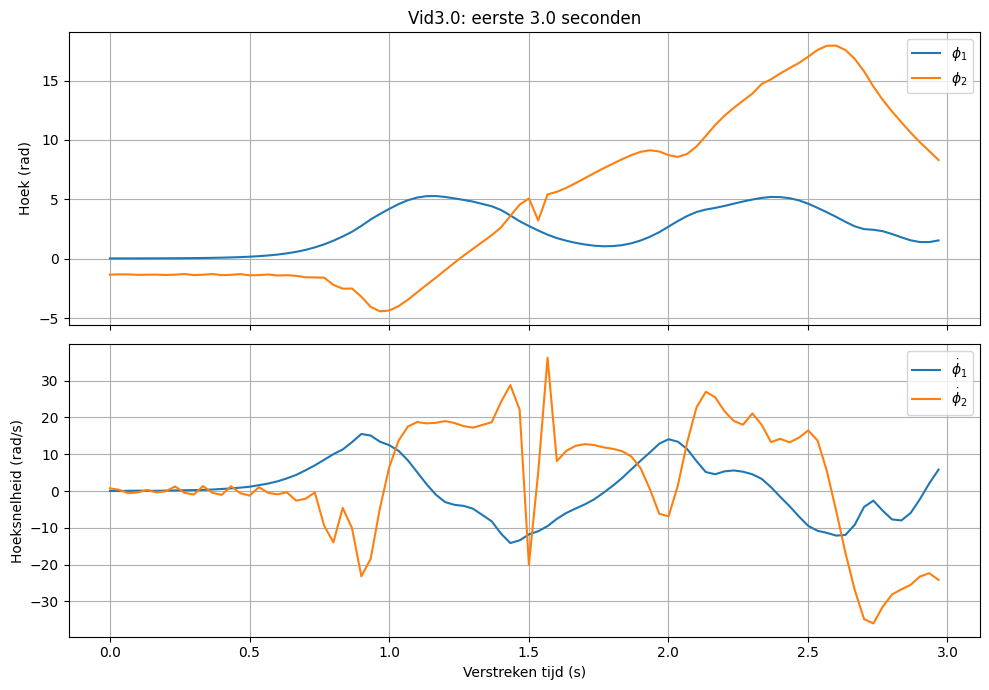

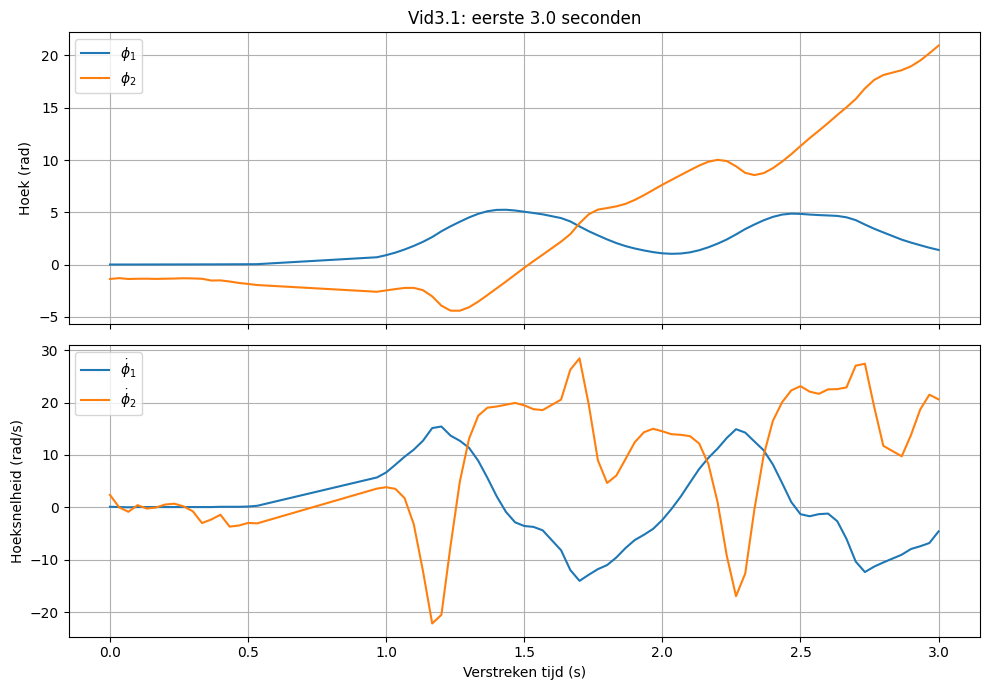

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def plot_start(green_file, red_file, title, end_time=3.0):
    green = pd.read_csv(green_file)
    red = pd.read_csv(red_file)

    data = pd.merge(
        green, red,
        on="time_s",
        suffixes=("_green", "_red")
    ).dropna()

    x1 = data["x_green"].to_numpy(dtype=float)
    y1 = -data["y_green"].to_numpy(dtype=float)
    x2 = data["x_red"].to_numpy(dtype=float)
    y2 = -data["y_red"].to_numpy(dtype=float)
    t = data["time_s"].to_numpy(dtype=float)

    # Cirkel fitten: cirkeldata en functie-invoer volgens circlefit
    circle_data = np.vstack((x1, y1))

    # Startwaarden: middelpunt en straal
    p0 = [np.mean(x1), np.mean(y1), np.std(x1)]

    # Residuen voor ieder gemeten punt
    def circle_residuals(data_xy, xc, yc, radius):
        x, y = data_xy
        return np.sqrt((x - xc)**2 + (y - yc)**2) - radius

    # curve_fit verwacht één residu per datapunt
    x0, y0, R = curve_fit(
        circle_residuals,
        (x1, y1),
        np.zeros(len(x1)),
        p0=p0
    )[0]

    # Hoeken vanaf de neerwaartse verticaal
    phi1 = np.unwrap(np.arctan2(x1 - x0, y1 - y0))
    phi2 = np.unwrap(np.arctan2(x2 - x1, y2 - y1))

    # Tijd vanaf de eerste meting
    tau = t - t[0]
    mask = tau <= end_time

    omega1 = np.gradient(phi1, t)
    omega2 = np.gradient(phi2, t)

    fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    ax[0].plot(tau[mask], phi1[mask], label=r"$\phi_1$")
    ax[0].plot(tau[mask], phi2[mask], label=r"$\phi_2$")
    ax[0].set_ylabel("Hoek (rad)")
    ax[0].set_title(f"{title}: eerste {end_time} seconden")
    ax[0].legend()
    ax[0].grid(True)

    ax[1].plot(tau[mask], omega1[mask], label=r"$\dot{\phi}_1$")
    ax[1].plot(tau[mask], omega2[mask], label=r"$\dot{\phi}_2$")
    ax[1].set_xlabel("Verstreken tijd (s)")
    ax[1].set_ylabel("Hoeksnelheid (rad/s)")
    ax[1].legend()
    ax[1].grid(True)

    plt.tight_layout()
    plt.show()


plot_start(filelist_green[0], filelist_red[0], "Vid3.0")
plot_start(filelist_green[1], filelist_red[1], "Vid3.1")